In [3]:
# =========================================================
# Cell 1: 全局可复现设置（必须放在最前面）
# =========================================================
import os
import random
import numpy as np

SEED = 42
# # 全局空间邻居数：用于空间图构建、NicheCompass 邻居采样、评估时空间邻接图重构
# neighbors_KNN = 4
# Python / Hash
os.environ["PYTHONHASHSEED"] = str(SEED)

# GPU 选择（保留你的设置）
os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ["CUDA_VISIBLE_DEVICES"] = "1"

# 为了更强复现，尽量单线程
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["NUMEXPR_NUM_THREADS"] = "1"

# CUDA 某些算子的确定性
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

random.seed(SEED)
np.random.seed(SEED)

import torch
torch.manual_seed(SEED)
torch.cuda.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

try:
    torch.use_deterministic_algorithms(True, warn_only=True)
except Exception as e:
    print("deterministic warn_only 模式未完全启用：", e)

torch.set_num_threads(1)

print(f"✅ 全局随机种子已固定为 {SEED}")

✅ 全局随机种子已固定为 42


使用SpaCET得出spot反卷积结果和肿瘤非肿瘤标签

In [4]:
# =========================================================
# Cell 0-1: 使用SpaCET得出spot反卷积结果和肿瘤非肿瘤标签
# =========================================================
import anndata as ad
import pandas as pd
import os

print("="*60)
# 1. 仅设置原始文件路径（删除输出路径，无新文件）
path_h5ad_original = "/home/zhangjunyi/xiangmu/nichecompass-main/datasets/12_colorectal_cancer_CRC/12_colorectal_cancer_CRC_h5ad/SN124_A551763_Rep2.h5ad"
path_spacet_csv = "/home/zhangjunyi/xiangmu/nichecompass-main/datasets/SpaCET_R_Result/12_colorectal_cancer_CRC/SN124_A551763_Rep2/SpaCET_CellFractions_Result.csv"

# 2. 读取原始 h5ad
print("正在读取原始 h5ad 文件...")
adata = ad.read_h5ad(path_h5ad_original)
print("文件读取成功！")
print("="*60)

# 3. 基因名格式校验（保留原逻辑）
print("【前 20 个基因名】：")
gene_names = adata.var.index.tolist()
print(gene_names[:20])
print("="*60)

if gene_names[0].startswith("ENSG"):
    print("❌ 检测结果：Ensembl ID 格式（需要转换为 Gene Symbol！）")
else:
    print("✅ 检测结果：标准 Gene Symbol 格式")
    print("🎉 完美！可以直接运行 SpaCET 代码，无需任何修改！")

# 4. 读取 SpaCET 结果 + Spot ID 对齐校验（保留原逻辑）
spacet_df = pd.read_csv(path_spacet_csv, index_col=0)
print(f"✅ 原始 h5ad 包含 {adata.n_obs} 个 Spots | SpaCET 结果包含 {spacet_df.shape[0]} 个 Spots")

common_spots = adata.obs_names.intersection(spacet_df.index)
if len(common_spots) == 0:
    raise ValueError("❌ 错误：原始 h5ad 和 SpaCET 结果没有匹配的 Spot ID！")
elif len(common_spots) < adata.n_obs:
    print(f"⚠️  警告：有 {adata.n_obs - len(common_spots)} 个 Spots 在 SpaCET 结果中未找到（已过滤）。")
    adata = adata[common_spots].copy()

# 5. 合并数据到 adata.obs（核心修复：自动覆盖重复列）
print("正在将CSV数据注入原始h5ad...")
spacet_df_aligned = spacet_df.reindex(adata.obs_names)

# 🔥 修复关键：删除原有重复列，实现覆盖效果
duplicate_cols = spacet_df_aligned.columns.intersection(adata.obs.columns)
if len(duplicate_cols) > 0:
    print(f"⚠️ 发现 {len(duplicate_cols)} 个重复列，将自动覆盖更新")
    adata.obs = adata.obs.drop(columns=duplicate_cols)

# 无冲突合并
adata.obs = adata.obs.join(spacet_df_aligned)

print("✅ 注入完成！adata.obs 中新增了以下列：")
print(spacet_df_aligned.columns.tolist())

# =========================================================
# 6. 物理清洗：剔除无病理注释及 exclude 的 Spot (新增逻辑)
# =========================================================
print("="*60)
print("正在执行最终数据清洗...")

# 确保列名正确
annot_col = 'pathology_annotation'
if annot_col in adata.obs.columns:
    # 1. 将注释转换为字符串并去除空格
    raw_annots = adata.obs[annot_col].astype(str).str.strip()
    
    # 2. 定义无效标签：包括 'exclude'、'nan'、'NaN'、'None' 和纯空格空值
    invalid_tags = ['exclude', 'nan', 'NaN', 'None', '', 'NA']
    
    valid_mask = (adata.obs[annot_col].notna()) & (~raw_annots.isin(invalid_tags))
    
    initial_count = adata.n_obs
    adata = adata[valid_mask].copy()
    removed_count = initial_count - adata.n_obs
    
    print(f"🧹 清理完毕：")
    print(f"   - 原始 Spot 数量: {initial_count}")
    print(f"   - 剔除无效/未标注 Spot 数量: {removed_count}")
    print(f"   - 最终保留有效 Spot 数量: {adata.n_obs}")
    
    if removed_count == 0:
        print("✅ 检查结果：该切片所有 Spot 均有有效病理标注。")
else:
    print(f"⚠️ 警告：未在 adata.obs 中找到 '{annot_col}' 列，跳过清洗步骤。")

# =========================================================
# 7. 直接覆盖保存原始h5ad
# =========================================================
print("="*60)
print(f"正在覆盖保存清洗后的原始文件：{path_h5ad_original}")
adata.write_h5ad(path_h5ad_original)
print("🎉 全部完成！SpaCET 结果已注入，且已物理剔除无标注区域。")

正在读取原始 h5ad 文件...
文件读取成功！
【前 20 个基因名】：
['MIR1302-2HG', 'FAM138A', 'OR4F5', 'AL627309.1', 'AL627309.3', 'AL627309.2', 'AL627309.5', 'AL627309.4', 'AP006222.2', 'AL732372.1', 'OR4F29', 'AC114498.1', 'OR4F16', 'AL669831.2', 'LINC01409', 'FAM87B', 'LINC01128', 'LINC00115', 'FAM41C', 'AL645608.6']
✅ 检测结果：标准 Gene Symbol 格式
🎉 完美！可以直接运行 SpaCET 代码，无需任何修改！
✅ 原始 h5ad 包含 1162 个 Spots | SpaCET 结果包含 1219 个 Spots
正在将CSV数据注入原始h5ad...
⚠️ 发现 35 个重复列，将自动覆盖更新
✅ 注入完成！adata.obs 中新增了以下列：
['Malignant', 'CAF', 'Endothelial', 'Plasma', 'B cell', 'T CD4', 'T CD8', 'NK', 'cDC', 'pDC', 'Macrophage', 'Mast', 'Neutrophil', 'Unidentifiable', 'B cell naive', 'B cell non-switched memory', 'B cell switched memory', 'B cell exhausted', 'T CD4 naive', 'Th1', 'Th2', 'Th17', 'Tfh', 'Treg', 'T CD8 naive', 'T CD8 central memory', 'T CD8 effector memory', 'T CD8 effector', 'T CD8 exhausted', 'cDC1 CLEC9A', 'cDC2 CD1C', 'cDC3 LAMP3', 'Macrophage M1', 'Macrophage M2', 'Macrophage other']
正在执行最终数据清洗...
🧹 清理完毕：
   - 原始 Spot 数量: 11

SpaCET
使用GMM计算阈值
高斯混合模型 (Gaussian Mixture Model, GMM)：假设数据由“低分（非肿瘤）”和“高分（肿瘤）”两个正态分布混合而成，寻找两个分布概率相交的点作为阈值。（最推荐，能处理方差不同的分布）

正在加载数据...
正在使用高斯混合模型 (GMM) 拟合数据分布...
✨ [无监督] 自动计算出的最优划分阈值为: 0.5272
✅ 图片已保存至: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET/GMM_Malignant_Threshold_Plot.png


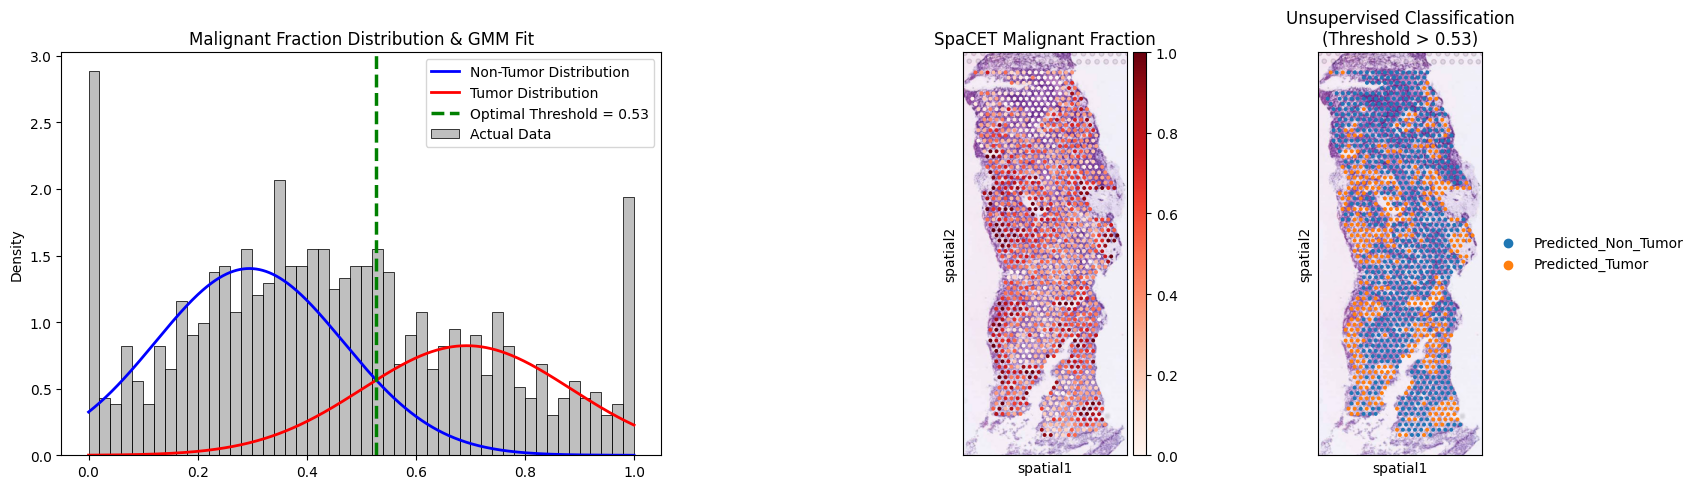

🎉 全部完成！所有文件已保存至指定文件夹


In [5]:
# =========================================================
# Cell 0-1: SpaCET 恶性分数 GMM 无监督自适应阈值计算
# =========================================================
import anndata as ad
import pandas as pd
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.mixture import GaussianMixture
import os

# 🔥 固定输出路径
SAVE_DIR = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET"
os.makedirs(SAVE_DIR, exist_ok=True)

# 1. 读取数据
file_path = "/home/zhangjunyi/xiangmu/nichecompass-main/datasets/12_colorectal_cancer_CRC/12_colorectal_cancer_CRC_h5ad/SN124_A551763_Rep2.h5ad"
print("正在加载数据...")
adata = ad.read_h5ad(file_path)

# 2. 提取 SpaCET 的 Malignant 分数并使用 GMM 拟合
malignant_scores = adata.obs['Malignant'].dropna().values
X = malignant_scores.reshape(-1, 1)

print("正在使用高斯混合模型 (GMM) 拟合数据分布...")
gmm = GaussianMixture(n_components=2, covariance_type='full', random_state=42)
gmm.fit(X)

means = gmm.means_.flatten()
class_non_tumor_idx, class_tumor_idx = np.argmin(means), np.argmax(means)

# 寻找边界交点
x_test = np.linspace(means[class_non_tumor_idx], means[class_tumor_idx], 1000).reshape(-1, 1)
preds = gmm.predict(x_test)
flip_index = np.where(preds[:-1] != preds[1:])[0]

optimal_threshold = x_test[flip_index[0]][0] if len(flip_index) > 0 else np.mean(means)
print(f"✨ [无监督] 自动计算出的最优划分阈值为: {optimal_threshold:.4f}")

# 3. 应用划分
col_name = f'Unsupervised_Pred_{optimal_threshold:.2f}'
adata.obs[col_name] = np.where(adata.obs['Malignant'] > optimal_threshold, 'Predicted_Tumor', 'Predicted_Non_Tumor')
adata.obs[col_name] = adata.obs[col_name].astype('category')

# 4. 可视化
fig, axs = plt.subplots(1, 3, figsize=(18, 5))

# 子图1: 分布
sns.histplot(malignant_scores, bins=50, stat='density', alpha=0.5, color='gray', ax=axs[0], label='Actual Data')
x_plot = np.linspace(0, 1, 1000).reshape(-1, 1)
pdf = np.exp(gmm.score_samples(x_plot))
resps = gmm.predict_proba(x_plot)
axs[0].plot(x_plot, pdf * resps[:, class_non_tumor_idx], color='blue', label='Non-Tumor Distribution', lw=2)
axs[0].plot(x_plot, pdf * resps[:, class_tumor_idx], color='red', label='Tumor Distribution', lw=2)
axs[0].axvline(optimal_threshold, color='green', linestyle='--', lw=2.5, label=f'Optimal Threshold = {optimal_threshold:.2f}')
axs[0].set_title('Malignant Fraction Distribution & GMM Fit')
axs[0].legend()

# 子图2 & 3: 空间图
sc.pl.spatial(adata, color='Malignant', title='SpaCET Malignant Fraction', size=1, cmap='Reds', ax=axs[1], show=False)
sc.pl.spatial(adata, color=col_name, title=f'Unsupervised Classification\n(Threshold > {optimal_threshold:.2f})', size=1, ax=axs[2], show=False)

plt.tight_layout()

# 🔥 保存输出
img_save_path = os.path.join(SAVE_DIR, "GMM_Malignant_Threshold_Plot.png")
plt.savefig(img_save_path, dpi=300, bbox_inches='tight')
print(f"✅ 图片已保存至: {img_save_path}")
plt.show()

label_df = adata.obs[[col_name, 'Malignant']].copy()
label_df.index.name = "Spot_ID"
label_df.to_csv(os.path.join(SAVE_DIR, "GMM_Tumor_NonTumor_Pred_Labels.csv"), encoding='utf-8-sig')

pd.DataFrame({"Metric": ["Optimal_GMM_Threshold"], "Value": [round(optimal_threshold, 4)]}).to_csv(
    os.path.join(SAVE_DIR, "GMM_Optimal_Threshold_Result.csv"), index=False, encoding='utf-8-sig')
print("🎉 全部完成！所有文件已保存至指定文件夹")

✅ 成功锁定 SpaCET 肿瘤反卷积比例列: 'Malignant'

===== 正在绘制空间分布对比图 =====


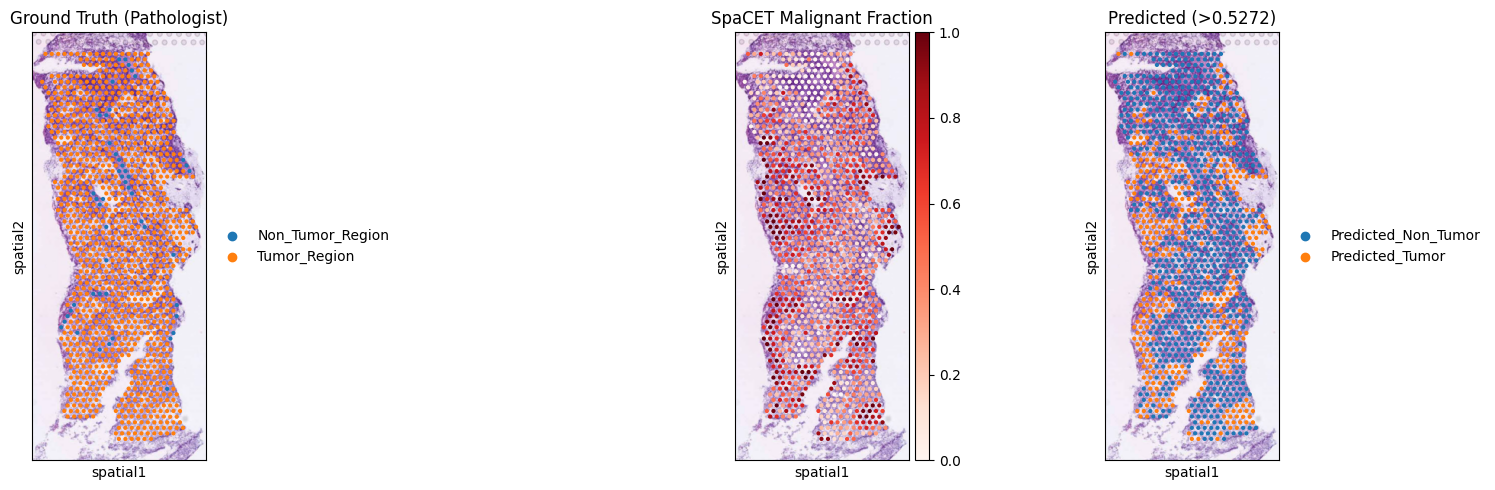


🚀 开始执行 SpaCET 基线模型的全维度指标评估...
🟢 [1/3] 宏观边界评估 (Supervised):
  --> 有效参与计算的 Spot 数量: 1162
  --> Adjusted Rand Index (ARI): -0.0093
  --> F1-Score (Tumor Region): 0.5323

🔵 [2/3] 微观特征纯度评估 (Unsupervised):
  --> 正在计算 PCA 作为底层转录组特征空间...
  --> Average Silhouette Width (ASW): 0.0562
  --> Silhouette Score on Malignant Fraction (SS-C Proxy): 0.5742
  --> Davies-Bouldin Index (DBI): 3.0842

🟣 [3/3] 物理空间连贯性指标 (Moran's I):
  --> 正在计算空间邻接图...


  0%|          | 0/100 [00:00<?, ?/s]

  --> 总体平均 Moran's Index (Moran's I): 0.3997

🎉 结直肠癌 SpaCET 基准测试完毕！所有指标已保存至：
   /home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET/评估结果_SpaCET_Baseline.csv


,Metric Name,Abbreviation,Value,Ideal Trend,Evaluation Dimension
0,Adjusted Rand Index,ARI,-0.0093,Closer to 1,Macro Boundary (Supervised)
1,F1-Score,F1,0.5323,Closer to 1,Macro Boundary (Supervised)
2,Average Silhouette Width,ASW,0.0562,Closer to 1,Micro Pureness (Unsupervised)
3,Silhouette Score on Coupling Scores,SS-C,0.5742,Closer to 1,Micro Pureness (Unsupervised)
4,Davies-Bouldin Index,DBI,3.0842,Closer to 0,Micro Pureness (Unsupervised)
5,Moran's Index,Moran's I,0.3997,Closer to 1 (>0),Spatial Topology (Physical)


💡 [探索] 对于该数据集，使 ARI 最高的硬切阈值其实是 0.10 (此时最高 ARI = 0.0861)


In [6]:
# =========================================================
# Cell 0-2: 基准评估 (病理注释 vs 硬阈值切割) - 全维度指标升级版
# 适配：结直肠癌 (CRC) 数据集 + pathology_annotation 列
# =========================================================
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq
import matplotlib.pyplot as plt
import os
import warnings
from sklearn.metrics import (
    adjusted_rand_score, 
    f1_score, 
    silhouette_score, 
    davies_bouldin_score
)

warnings.filterwarnings("ignore")

# ==========================================
# 0. 自动寻找 SpaCET 肿瘤占比列 (智能防报错)
# ==========================================
possible_names = ['Malignant', 'Tumor', 'malignant', 'tumor', 'Cancer', 'cancer']
spacet_col = None

for name in possible_names:
    if name in adata.obs.columns:
        spacet_col = name
        break

if spacet_col is None:
    print("❌ 严重错误: 在 adata.obs 中没有找到 SpaCET 预测的肿瘤细胞比例列！")
    print("当前所有的列名如下，请检查 Cell 1 是否成功合并了数据：")
    print(adata.obs.columns.tolist())
    raise KeyError("Missing SpaCET fraction column.")
else:
    print(f"✅ 成功锁定 SpaCET 肿瘤反卷积比例列: '{spacet_col}'")

# ===================== 核心修改：自定义病理标签映射 =====================
# 1. 严格按照你指定的规则定义结直肠癌 (CRC) 映射
gt_map_int = {
   'tumor': 1, 'tumor&stroma_IC med to high': 1, 
   'stroma_fibroblastic_IC med': 0, 'stroma_fibroblastic_IC high': 0
}

gt_map_str = {
 'tumor': 'Tumor_Region', 
 'tumor&stroma_IC med to high': 'Tumor_Region', 
 'stroma_fibroblastic_IC med': 'Non_Tumor_Region', 
 'stroma_fibroblastic_IC high': 'Non_Tumor_Region'
   
}

# 2. 从 pathology_annotation 生成真实标签（专属 CRC 的列名）
adata.obs['Ground_Truth_Binary'] = adata.obs['pathology_annotation'].map(gt_map_str).astype('category')
gt_labels_for_math = adata.obs['pathology_annotation'].map(gt_map_int).values

# ==========================================
# 3. 生成预测标签 (SpaCET 恶性分数阈值切割)
# ==========================================
# 自动读取上一步的最优阈值，如果没有则使用 0.5282 作为默认
threshold = optimal_threshold

adata.obs[f'Pred_Threshold_{threshold:.4f}'] = np.where(
    adata.obs[spacet_col] > threshold, 
    'Predicted_Tumor', 
    'Predicted_Non_Tumor'
)
adata.obs[f'Pred_Threshold_{threshold:.4f}'] = adata.obs[f'Pred_Threshold_{threshold:.4f}'].astype('category')
pred_labels_for_math = (adata.obs[spacet_col] > threshold).astype(float).values

# ==========================================
# 4. 空间可视化对比
# ==========================================
print("\n===== 正在绘制空间分布对比图 =====")
try:
    fig, axs = plt.subplots(1, 3, figsize=(18, 5))
    sc.pl.spatial(adata, color='Ground_Truth_Binary', title='Ground Truth (Pathologist)', size=1, ax=axs[0], show=False)
    sc.pl.spatial(adata, color=spacet_col, title=f'SpaCET {spacet_col} Fraction', size=1, cmap='Reds', ax=axs[1], show=False)
    sc.pl.spatial(adata, color=f'Pred_Threshold_{threshold:.4f}', title=f'Predicted (>{threshold:.4f})', size=1, ax=axs[2], show=False)
    plt.tight_layout()
    plt.show()
except Exception as e:
    print(f"可视化失败: {e}")

# ==========================================
# 5. 全维度空间与特征指标综合评估 (SpaCET Baseline)
# ==========================================
print("\n" + "="*60)
print("🚀 开始执行 SpaCET 基线模型的全维度指标评估...")
print("="*60)

# --- 模块一：宏观边界评估 (Supervised: ARI, F1) ---
valid_mask = ~np.isnan(gt_labels_for_math)  # 过滤空值
y_true = gt_labels_for_math[valid_mask]
y_pred = pred_labels_for_math[valid_mask]

ari_val = adjusted_rand_score(y_true, y_pred)
f1_val = f1_score(y_true, y_pred, pos_label=1.0, average='binary')

print(f"🟢 [1/3] 宏观边界评估 (Supervised):")
print(f"  --> 有效参与计算的 Spot 数量: {len(y_true)}")
print(f"  --> Adjusted Rand Index (ARI): {ari_val:.4f}")
print(f"  --> F1-Score (Tumor Region): {f1_val:.4f}")

# --- 模块二：微观特征纯度评估 (Unsupervised: ASW, SS-C, DBI) ---
print(f"\n🔵 [2/3] 微观特征纯度评估 (Unsupervised):")
if 'X_pca' not in adata.obsm:
    print("  --> 正在计算 PCA 作为底层转录组特征空间...")
    sc.pp.normalize_total(adata, target_sum=1e4)
    sc.pp.log1p(adata)
    sc.tl.pca(adata, svd_solver='arpack')

X_features = adata.obsm['X_pca']

asw_val = silhouette_score(X_features, pred_labels_for_math)
dbi_val = davies_bouldin_score(X_features, pred_labels_for_math)

# SS-C Proxy：使用 SpaCET 的连续分数计算自身划分的紧凑度
X_spacet_feature = adata.obs[spacet_col].values.reshape(-1, 1)
ssc_val = silhouette_score(X_spacet_feature, pred_labels_for_math)

print(f"  --> Average Silhouette Width (ASW): {asw_val:.4f}")
print(f"  --> Silhouette Score on {spacet_col} Fraction (SS-C Proxy): {ssc_val:.4f}")
print(f"  --> Davies-Bouldin Index (DBI): {dbi_val:.4f}")

# --- 模块三：空间物理聚集度 (Spatial Topology: Moran's I) ---
print(f"\n🟣 [3/3] 物理空间连贯性指标 (Moran's I):")
if 'spatial_connectivities' not in adata.obsp:
    print("  --> 正在计算空间邻接图...")
    sq.gr.spatial_neighbors(adata, coord_type="generic", spatial_key="spatial", n_neighs=6)

tmp_adata = sc.AnnData(X=pred_labels_for_math.reshape(-1, 1).astype(float))
tmp_adata.obs_names = adata.obs_names
tmp_adata.var_names = ['SpaCET_Tumor_Pred']
tmp_adata.obsp['spatial_connectivities'] = adata.obsp['spatial_connectivities']

sq.gr.spatial_autocorr(tmp_adata, mode="moran", genes=['SpaCET_Tumor_Pred'], n_perms=100, n_jobs=-1)
moran_val = tmp_adata.uns["moranI"].loc['SpaCET_Tumor_Pred', 'I']

print(f"  --> 总体平均 Moran's Index (Moran's I): {moran_val:.4f}")

# ==========================================
# 6. 汇总并保存所有指标至 CSV
# ==========================================
# 指定保存路径
SAVE_PATH = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET"
os.makedirs(SAVE_PATH, exist_ok=True)
csv_save_path = os.path.join(SAVE_PATH, "评估结果_SpaCET_Baseline.csv")

# 构建与你自定义方法一致的结果表格
results_df = pd.DataFrame({
    "Metric Name": [
        "Adjusted Rand Index", 
        "F1-Score", 
        "Average Silhouette Width", 
        "Silhouette Score on Coupling Scores", 
        "Davies-Bouldin Index", 
        "Moran's Index"
    ],
    "Abbreviation": ["ARI", "F1", "ASW", "SS-C", "DBI", "Moran's I"],
    "Value": [
        round(ari_val, 4), 
        round(f1_val, 4), 
        round(asw_val, 4), 
        round(ssc_val, 4), 
        round(dbi_val, 4), 
        round(moran_val, 4)
    ],
    "Ideal Trend": [
        "Closer to 1", "Closer to 1", "Closer to 1", 
        "Closer to 1", "Closer to 0", "Closer to 1 (>0)"
    ],
    "Evaluation Dimension": [
        "Macro Boundary (Supervised)", 
        "Macro Boundary (Supervised)", 
        "Micro Pureness (Unsupervised)", 
        "Micro Pureness (Unsupervised)", 
        "Micro Pureness (Unsupervised)", 
        "Spatial Topology (Physical)"
    ]
})

results_df.to_csv(csv_save_path, index=False, encoding="utf-8-sig")

print("\n" + "="*60)
print(f"🎉 结直肠癌 SpaCET 基准测试完毕！所有指标已保存至：\n   {csv_save_path}")
print("="*60)
display(results_df)

# [探索选项] 额外保存一份最优阈值探索记录（可选保留）
best_t, best_ari = max(
    ((t, adjusted_rand_score(gt_labels_for_math[valid_mask], (adata.obs[spacet_col] > t).astype(float).values[valid_mask])) 
     for t in np.arange(0.1, 0.9, 0.05)), 
    key=lambda x: x[1]
)
print(f"💡 [探索] 对于该数据集，使 ARI 最高的硬切阈值其实是 {best_t:.2f} (此时最高 ARI = {best_ari:.4f})")

In [7]:
# =========================================================
# Cell 2: 环境配置与 NicheCompass 导入
# =========================================================
import os
import sys
import warnings

warnings.filterwarnings("ignore")

import torch
import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import decoupler as dc
import scipy.sparse as sp
from io import StringIO
from sklearn.preprocessing import MinMaxScaler

LOCAL_SRC = "/home/zhangjunyi/xiangmu/nichecompass-main/src"
if LOCAL_SRC not in sys.path:
    sys.path.insert(0, LOCAL_SRC)

import nichecompass as nc

print("✅ CUDA 可用状态:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("✅ 当前使用 GPU:", torch.cuda.get_device_name(0))
print("✅ NicheCompass 路径:", nc.__file__)
print("✅ 当前 SEED:", SEED)

✅ CUDA 可用状态: True
✅ 当前使用 GPU: A100 80GB PCIe
✅ NicheCompass 路径: /home/zhangjunyi/xiangmu/nichecompass-main/src/nichecompass/__init__.py
✅ 当前 SEED: 42


In [8]:
# =========================================================
# Cell 3: 从四元组文件构建代谢通讯轴知识库
# =========================================================
from IPython.display import display
import os
import pandas as pd

print("=== Step 1: 从文件加载代谢通讯轴四元组知识库 ===")

# 1. 四元组文件路径
axis_table_path = "/home/zhangjunyi/xiangmu/nichecompass-main/data/pre_data/siyuanzu/my_metabolite_network.csv"

if not os.path.exists(axis_table_path):
    raise FileNotFoundError(f"❌ 未找到四元组文件: {axis_table_path}")

# 2. 读取四元组文件
axis_table = pd.read_csv(axis_table_path, encoding="utf-8-sig")

# 3. 检查必须列是否存在
required_cols = [
    "TMCN_Name",
    "Source_Pathways",
    "Source_Genes",
    "Target_Genes",
    "Biologic_Meaning"
]

missing_cols = [c for c in required_cols if c not in axis_table.columns]
if len(missing_cols) > 0:
    raise ValueError(f"❌ 四元组文件缺少必要列: {missing_cols}")

# 4. 清理字符串空格，避免后面匹配失败
for col in required_cols:
    axis_table[col] = axis_table[col].astype(str).str.strip()

# 5. 自动生成代谢轴名称
AXES = [
    x.replace("TMCN_", "").replace("_Axis", "")
    for x in axis_table["TMCN_Name"]
]

# 6. 工具函数
def split_items(x):
    return [i.strip() for i in str(x).split(",") if i.strip()]

def get_valid_genes(adata, genes):
    return [g for g in genes if g in adata.var_names]

# 7. 加载带有 SpaCET 结果的空间转录组数据
file_path = "/home/zhangjunyi/xiangmu/nichecompass-main/datasets/12_colorectal_cancer_CRC/12_colorectal_cancer_CRC_h5ad/SN124_A551763_Rep2.h5ad"
adata = sc.read_h5ad(file_path)

print(f"✅ 四元组文件加载成功: {axis_table_path}")
print(f"✅ 共读取到 {axis_table.shape[0]} 条代谢通讯轴")
print(f"✅ AXES = {AXES}")
print(f"✅ 数据加载成功: {adata.n_obs} spots, {adata.n_vars} genes")

display(axis_table)

=== Step 1: 从文件加载代谢通讯轴四元组知识库 ===
✅ 四元组文件加载成功: /home/zhangjunyi/xiangmu/nichecompass-main/data/pre_data/siyuanzu/my_metabolite_network.csv
✅ 共读取到 10 条代谢通讯轴
✅ AXES = ['Lactate', 'Adenosine', 'PGE2', 'Glutamine', 'Succinate', 'Kynurenine', 'ATP', 'S1P', 'LPA', 'Glutamate']
✅ 数据加载成功: 1162 spots, 36601 genes


,TMCN_Name,Source_Pathways,Source_Genes,Target_Genes,Biologic_Meaning
0,TMCN_Lactate_Axis,"Hypoxia,EGFR,PI3K,MAPK","SLC2A1,HK2,PKM,LDHA,LDHB,SLC16A3","SLC16A1,SLC16A7,HCAR1,HCAR2",乳酸_肿瘤酸化瓦伯格效应与基质反向代谢共生
1,TMCN_Adenosine_Axis,"Hypoxia,TGFb,NFkB,MAPK","ENTPD1,ENTPD2,NT5E,CD38,ENPP1,NT5C2","ADORA1,ADORA2A,ADORA2B,ADORA3,SLC29A1,SLC29A2",腺苷_ATP水解级联驱动的强效免疫抑制与M2极化
2,TMCN_PGE2_Axis,"NFkB,JAK-STAT,Hypoxia,MAPK,TNFa","PLA2G4A,PTGS2,PTGES,ABCC4,SLCO2A1","PTGER1,PTGER2,PTGER3,PTGER4",前列腺素E2_成纤维细胞激活与促癌炎症微环境重塑
3,TMCN_Glutamine_Axis,"PI3K,MAPK,JAK-STAT,TGFb,WNT","GLUL,SLC38A1,SLC38A3,SLC38A5","SLC1A5,SLC7A5,SLC38A2,GLS,GLUD1",谷氨酰胺_基质向肿瘤供能的代谢寄生与大分子合成
4,TMCN_Succinate_Axis,"Hypoxia,NFkB,TNFa","SLC13A2,SLC13A3,SLC25A10",SUCNR1,琥珀酸_缺血坏死区释放驱动的TAM致瘤极化与血管生成
5,TMCN_Kynurenine_Axis,"JAK-STAT,NFkB,TGFb","IDO1,TDO2,KYNU,SLC7A5",AHR,犬尿氨酸_色氨酸剥夺与AHR介导的效应T细胞耗竭
6,TMCN_ATP_Axis,"Hypoxia,p53,TNFa","PANX1,SLC17A9","P2RX7,P2RY2,P2RY11",胞外ATP_坏死边缘释放的促炎性危险信号(DAMP)传导
7,TMCN_S1P_Axis,"NFkB,PI3K,MAPK","SPHK1,SPHK2,SPNS2","S1PR1,S1PR2,S1PR3",鞘氨醇-1-磷酸_脂质信号驱动的内皮血管生成与免疫趋化
8,TMCN_LPA_Axis,"PI3K,MAPK,TGFb","ENPP2,PLA2G4A,LPCAT1","LPAR1,LPAR2,LPAR3,LPAR5",溶血磷脂酸_成纤维细胞基质重塑与肿瘤高侵袭性
9,TMCN_Glutamate_Axis,"PI3K,MAPK,Hypoxia","GLS,SLC1A5,SLC7A11","GRM3,GRM5,GRIN1",谷氨酸_突触样代谢通讯与微环境神经可塑性


In [9]:
# =========================================================
# Cell 4: 连续功能分数推断与解耦 (Step 2)
# =========================================================
print("=== Step 2: 计算 Spot 级连续分数 (绝对无监督解耦) ===")

# 1. PROGENy (Pathway)
print("--> 正在计算 Pathway_score (PROGENy)...")
net_progeny = dc.get_progeny(organism="human", top=500)
dc.run_mlm(mat=adata, net=net_progeny, source="source", target="target", weight="weight", verbose=False, use_raw=False)
df_pathway = dc.get_acts(adata, obsm_key="mlm_estimate").to_df()
df_pathway.columns = [c.strip().replace("-", "_").replace(" ", "_") for c in df_pathway.columns]

# 2. AUCell (Enzyme)
print("--> 正在计算 Enzyme_score (AUCell)...")
enzyme_records = [{"source": row["TMCN_Name"].replace("TMCN_", "").replace("_Axis", ""), "target": g} 
                  for _, row in axis_table.iterrows() for g in split_items(row["Source_Genes"]) if g in adata.var_names]
dc.run_aucell(mat=adata, net=pd.DataFrame(enzyme_records), source="source", target="target", min_n=1, verbose=False, use_raw=False)
df_enzyme = dc.get_acts(adata, obsm_key="aucell_estimate").to_df()

# 3. 归一化
scaler = MinMaxScaler()
df_pathway_scaled = pd.DataFrame(scaler.fit_transform(df_pathway), index=df_pathway.index, columns=df_pathway.columns)
df_enzyme_scaled = pd.DataFrame(scaler.fit_transform(df_enzyme), index=df_enzyme.index, columns=df_enzyme.columns)

# 4. Receptor & 综合打分
print("--> 正在计算 Sender_score 与 Receiver_score...")
def calc_receptor_score(genes):
    valid = get_valid_genes(adata, genes)
    if not valid: return np.zeros(adata.n_obs)
    X_sub = adata[:, valid].X
    mean_exp = np.asarray(X_sub.mean(axis=1)).reshape(-1) if sp.issparse(X_sub) else np.asarray(X_sub).mean(axis=1).reshape(-1)
    return scaler.fit_transform(mean_exp.reshape(-1, 1)).flatten()

for _, row in axis_table.iterrows():
    ax = row["TMCN_Name"].replace("TMCN_", "").replace("_Axis", "")
    pathways = [p.strip().replace("-", "_").replace(" ", "_") for p in split_items(row["Source_Pathways"])]
    target_genes = split_items(row["Target_Genes"])
    
    valid_paths = [p for p in pathways if p in df_pathway_scaled.columns]
    adata.obs[f"{ax}_Sender_Score"] = df_pathway_scaled[valid_paths].mean(axis=1).values * df_enzyme_scaled[ax].values
    adata.obs[f"{ax}_Receiver_Score"] = calc_receptor_score(target_genes)

print("✅ 所有连续分数提取完毕！")
display(adata.obs[[c for c in adata.obs.columns if "Sender_Score" in c or "Receiver_Score" in c]].head())

=== Step 2: 计算 Spot 级连续分数 (绝对无监督解耦) ===
--> 正在计算 Pathway_score (PROGENy)...
--> 正在计算 Enzyme_score (AUCell)...
--> 正在计算 Sender_score 与 Receiver_score...
✅ 所有连续分数提取完毕！


,Lactate_Sender_Score,Lactate_Receiver_Score,Adenosine_Sender_Score,Adenosine_Receiver_Score,PGE2_Sender_Score,PGE2_Receiver_Score,Glutamine_Sender_Score,Glutamine_Receiver_Score,Succinate_Sender_Score,Succinate_Receiver_Score,Kynurenine_Sender_Score,Kynurenine_Receiver_Score,ATP_Sender_Score,ATP_Receiver_Score,S1P_Sender_Score,S1P_Receiver_Score,LPA_Sender_Score,LPA_Receiver_Score,Glutamate_Sender_Score,Glutamate_Receiver_Score
AAACCGTTCGTCCAGG-1,0.304397,0.0,0.000000,0.333333,0.16996,0.0,0.000000,0.2,0.0,0.0,0.0,0.25,0.078582,0.0,0.0,0.0,0.000000,0.0,0.000000,0.0
AAACGAAGAACATACC-1,0.083744,0.0,0.000000,0.000000,0.00000,0.0,0.000000,0.1,0.0,0.0,0.0,0.00,0.000000,0.0,0.0,0.0,0.000000,0.0,0.099116,0.0
AAACGAGACGGTTGAT-1,0.247463,0.0,0.072752,0.000000,0.00000,0.0,0.144842,0.1,0.0,0.0,0.0,0.00,0.000000,0.0,0.0,0.0,0.099185,0.0,0.000000,0.0
AAACGGTTGCGAACTG-1,0.018036,0.0,0.000000,0.666667,0.00000,0.0,0.000000,0.2,0.0,0.0,0.0,0.00,0.000000,0.0,0.0,0.0,0.000000,0.0,0.120959,0.0
AAACTCGGTTCGCAAT-1,0.086398,0.0,0.000000,0.000000,0.00000,0.0,0.004434,0.4,0.0,0.0,0.0,0.00,0.000000,0.0,0.0,0.0,0.000000,0.0,0.402138,0.0


===== Cell 4: Step 3 - 无监督训练与生成“微型生态位” =====
注意：这段代码中，NicheCompass 只看 高变基因和基础空间图，完全屏蔽了刚才算出来的代谢特征！

In [ ]:
# =========================================================
# Cell 5: NicheCompass 无监督拓扑学习与过聚类
# =========================================================
print("=== Step 3: NicheCompass 构建物理联通图与微型生态位骨架 ===")

# 1) 基础过滤
adata_model = adata.copy()
sc.pp.filter_genes(adata_model, min_cells=10)

# 2) 先找 HVG（只打标记，不立刻 subset）
sc.pp.highly_variable_genes(
    adata_model,
    n_top_genes=3000,
    flavor="seurat_v3",
    subset=False
)

# 3) 强制保留所有 TMCN 四元组中的 Source_Genes + Target_Genes
tmcn_gene_set = set()

for _, row in axis_table.iterrows():
    tmcn_gene_set.update(split_items(row["Source_Genes"]))
    tmcn_gene_set.update(split_items(row["Target_Genes"]))

tmcn_gene_set = {g for g in tmcn_gene_set if g in adata_model.var_names}

# 4) 最终保留 = HVG ∪ TMCN genes
keep_mask = adata_model.var["highly_variable"].values | adata_model.var_names.isin(list(tmcn_gene_set))
adata_model = adata_model[:, keep_mask].copy()

print(f"✅ HVG 保留后基因数: {adata_model.n_vars}")
print(f"✅ 强制保留的 TMCN 基因数: {len(tmcn_gene_set)}")

# 2) 矩阵清洗与过滤 (优化：合并执行处理 0 计数点和 NaN/Inf 清洗)
counts_key = "counts" if "counts" in adata_model.layers else None
x_for_lib = adata_model.layers[counts_key] if counts_key is not None else adata_model.X
lib_size = np.asarray(x_for_lib.sum(axis=1)).reshape(-1)
valid_spot_mask = np.isfinite(lib_size) & (lib_size > 0)
adata_model = adata_model[valid_spot_mask].copy()
print(f"✅ 保留 {adata_model.n_obs} 个有效spots（已移除总计数为0的spots）")

mat = adata_model.layers.get(counts_key) if counts_key else adata_model.X
if sp.issparse(mat):
    mat = mat.copy()
    mat.data = np.nan_to_num(mat.data, nan=0.0, posinf=0.0, neginf=0.0)
    mat.data = np.clip(mat.data, a_min=0, a_max=None)
else:
    mat = np.nan_to_num(mat, nan=0.0, posinf=0.0, neginf=0.0)
    mat = np.clip(mat, a_min=0, a_max=None)
if counts_key: adata_model.layers[counts_key] = mat
else: adata_model.X = mat


# 3) 空间图 + LR先验
sq.gr.spatial_neighbors(adata_model, coord_type="generic", spatial_key="spatial", n_neighs=8)
cache_dir = "/home/zhangjunyi/xiangmu/nichecompass-main/cache_nichenet"
gp_dict = nc.utils.extract_gp_dict_from_nichenet_lrt_interactions(
    species="human", version="v2", keep_target_genes_ratio=0.25, max_n_target_genes_per_gp=50,
    load_from_disk=True, lr_network_file_path=f"{cache_dir}/nichenet_lr_network.csv",
    ligand_target_matrix_file_path=f"{cache_dir}/nichenet_ligand_target_matrix.csv"
)
nc.utils.add_gps_from_gp_dict_to_adata(gp_dict=gp_dict, adata=adata_model)

# 4) Initialize + Train Model
model = nc.models.NicheCompass(
    adata_model, counts_key=counts_key, adj_key="spatial_connectivities",
    gp_names_key="nichecompass_gp_names", active_gp_names_key="nichecompass_active_gp_names",
    gp_targets_mask_key="nichecompass_gp_targets", gp_targets_categories_mask_key="nichecompass_gp_targets_categories",
    gp_sources_mask_key="nichecompass_gp_sources", gp_sources_categories_mask_key="nichecompass_gp_sources_categories",
    latent_key="nichecompass_latent", conv_layer_encoder="gcnconv", active_gp_thresh_ratio=0.01,
)
# 全图训练所需的完整规模
full_node_batch_size = adata_model.n_obs
full_edge_batch_size = int(adata_model.obsp["spatial_connectivities"].nnz)

print(f"全量 nodes: {full_node_batch_size}")
print(f"全量 edges: {full_edge_batch_size}")

model.train(
    n_epochs=50, n_epochs_all_gps=10, lr=1e-4, lambda_edge_recon=1e5,
    lambda_gene_expr_recon=100.0, lambda_l1_masked=0.0, edge_batch_size=full_edge_batch_size,
    node_batch_size=full_node_batch_size, n_sampled_neighbors=4, edge_val_ratio=0.0, node_val_ratio=0.0,
    use_cuda_if_available=True, verbose=False
)

# 5) 保存结果
save_base_dir = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My"
file_prefix = "SN124_A551763_Rep2"
os.makedirs(save_base_dir, exist_ok=True)

adata_model.write_h5ad(os.path.join(save_base_dir, f"{file_prefix}.h5ad"))
model.save(
    os.path.join(save_base_dir, f"{file_prefix}_model"),
    overwrite=True
)
print("✅ [AnnData & Model] 结果已保存！\n=== Step 3 & 4 全部完成 ===")

✅ [1/2] AnnData 已从 /home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My/SN124_A551763_Rep2.h5ad 加载
--- INITIALIZING NEW NETWORK MODULE: VARIATIONAL GENE PROGRAM GRAPH AUTOENCODER ---
LOSS -> include_edge_recon_loss: True, include_gene_expr_recon_loss: True, rna_recon_loss: nb
NODE LABEL METHOD -> one-hop-norm
ACTIVE GP THRESHOLD RATIO -> 0.01
LOG VARIATIONAL -> True
ONE HOP GCN NORM RNA NODE LABEL AGGREGATOR
ENCODER -> n_input: 3033, n_cat_covariates_embed_input: 0, n_hidden: 1326, n_latent: 1226, n_addon_latent: 100, n_fc_layers: 1, n_layers: 1, conv_layer: gcnconv, n_attention_heads: 0, dropout_rate: 0.0, 
COSINE SIM GRAPH DECODER -> dropout_rate: 0.0
MASKED TARGET RNA DECODER -> n_prior_gp_input: 1226, n_addon_gp_input: 100, n_cat_covariates_embed_input: 0, n_output: 3033
MASKED SOURCE RNA DECODER -> n_prior_gp_input: 1226, n_addon_gp_input: 100, n_cat_covariates_embed_input: 0, n_output: 3033


✅ [2/2] NicheCompass 模型已从 /home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My/SN124_A551763_Rep2_model 加载
⚠️ 警告: 在 layers 中未找到 'counts'，将默认使用 adata_model.X
✅ 关键参数变量已恢复，可继续运行后续代码
✅ 原生聚类完成：8 类


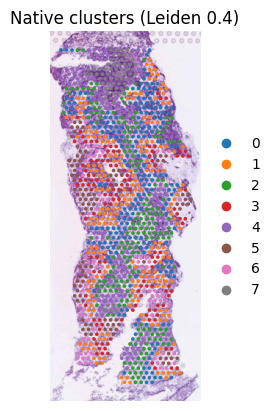

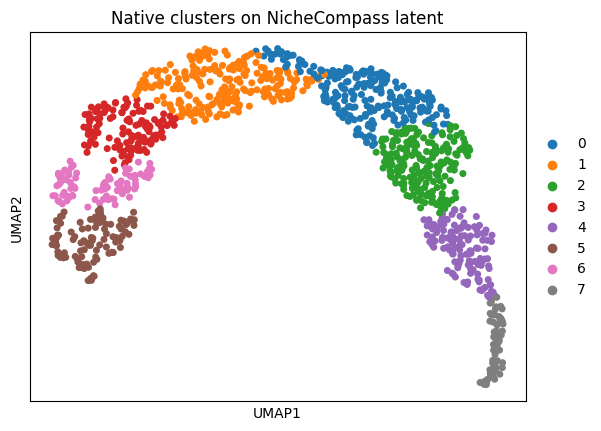

In [11]:
# ===================== Cell 6 =====================
# =========================================================
# 前置步骤：加载 Step3 保存的结果 (AnnData + 模型)
# =========================================================
import os
import scanpy as sc
# 假设 nichecompass 已正确导入为 nc
import nichecompass as nc 

save_base_dir = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My"
file_prefix = "SN124_A551763_Rep2"

# -------------------------- 2. 加载 AnnData 对象 --------------------------
adata_load_path = os.path.join(save_base_dir, f"{file_prefix}.h5ad")
adata_model = sc.read_h5ad(adata_load_path)
print(f"✅ [1/2] AnnData 已从 {adata_load_path} 加载")

# -------------------------- 3. 加载 NicheCompass 模型 --------------------------
model_load_dir = os.path.join(save_base_dir, f"{file_prefix}_model")
# 注意：load 函数需要传入对应的 adata_model 以恢复图结构等信息
model = nc.models.NicheCompass.load(
    dir_path=model_load_dir,
    adata=adata_model
)
print(f"✅ [2/2] NicheCompass 模型已从 {model_load_dir} 加载")

# -------------------------- 4. 恢复/定义关键参数变量 (供后续代码使用) --------------------------
# 这些变量名必须与你训练时的代码保持一致
latent_key = "nichecompass_latent"

# ✅ 修复：动态检查 counts_key，不要硬编码
if "counts" in adata_model.layers:
    counts_key = "counts"
else:
    counts_key = None  # 如果 layers 里没有 counts，就设为 None (使用 .X)
    print("⚠️ 警告: 在 layers 中未找到 'counts'，将默认使用 adata_model.X")

adj_key = "spatial_connectivities"
node_batch_size = adata_model.n_obs  # 与训练时保持一致

print("✅ 关键参数变量已恢复，可继续运行后续代码")



# =========================================================
# Step3: 训练后仅查看 NicheCompass 原生聚类结果（无二次划分）
# 直接接在 model.train(...) 后运行
# =========================================================

# 1) 提取 latent（与训练保持同一 counts_key / adj_key）
adata_model.obsm[latent_key] = model.get_latent_representation(
    adata=adata_model,
    counts_key=counts_key,
    adj_key=adj_key,
    node_batch_size=node_batch_size,
)

# 2) 官方教程风格：latent 上建图 + UMAP
sc.pp.neighbors(
    adata_model,
    use_rep=latent_key,
    key_added=latent_key,
    random_state=SEED
)

sc.tl.umap(
    adata_model,
    neighbors_key=latent_key,
    random_state=SEED
)

# 3) 原生聚类（不过度切碎）
native_cluster_key = "latent_leiden_0.6"
sc.tl.leiden(
    adata_model,
    neighbors_key=latent_key,
    key_added=native_cluster_key,
    resolution=0.6,
    random_state=SEED
)

print(f"✅ 原生聚类完成：{adata_model.obs[native_cluster_key].nunique()} 类")

# 4) 仅可视化原生聚类（空间 + UMAP）
sc.pl.spatial(
    adata_model,
    color=native_cluster_key,
    size=1,
    title="Native clusters (Leiden 0.4)",
    frameon=False
)
sc.pl.umap(
    adata_model,
    color=native_cluster_key,
    title="Native clusters on NicheCompass latent"
)



阶段二：数据驱动的自适应阈值与代谢投影 (Data-Driven Projection)
step4——step5
先通过 NicheCompass 基于空间坐标构建组织的物理联通图，无监督学习生成微生态位基础骨架，锁定每个测序 spot 的真实空间邻居关系；
为每条代谢通讯轴计算空间耦合分数，结合 spot 自身的代谢发送能力与周边邻居的接收能力，量化真实的空间通讯潜力；
用高斯混合模型（GMM）为每条轴独立自适应设定活性阈值，分位数法兜底，再基于阈值完成微生态位的精准分型，对过渡区做后续空间拓扑优化；
最终通过分布可视化与空间置换检验，验证结果的生物学真实性与统计稳健性，排除随机噪音干扰。

=== 阶段二: 代谢统计初判 + low_malig_gate spot级过滤版 ===
--> 1. 计算空间加权代谢通讯分数 (Coupling Score)...
--> 2. 学习每条代谢轴的自适应阈值 (GMM / Robust Dynamic)...


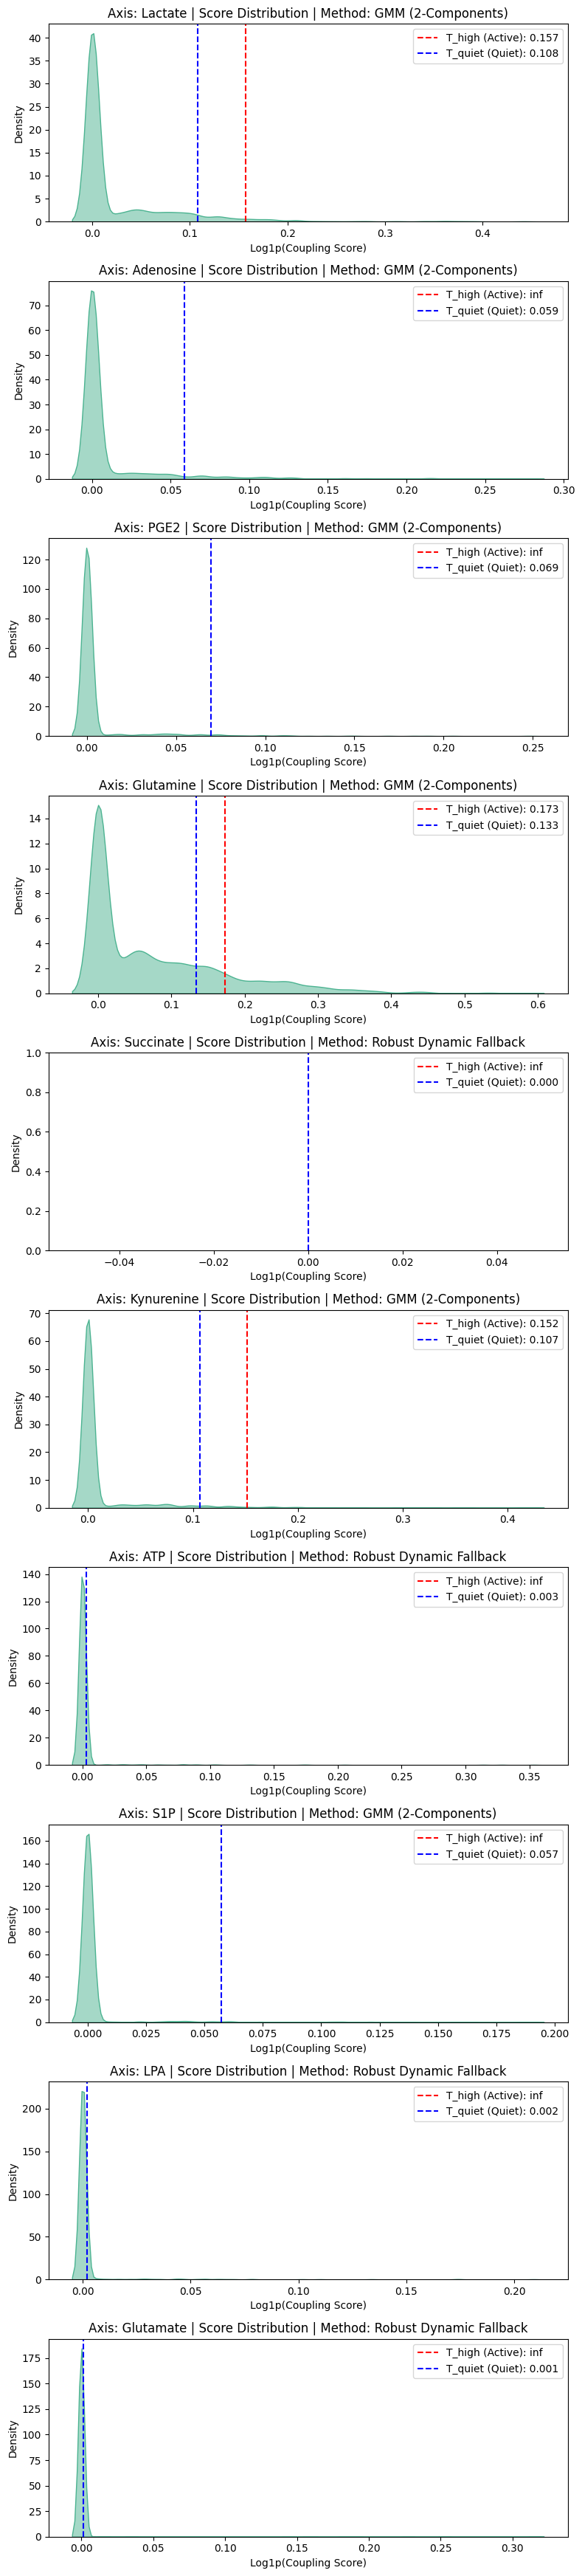


--- 自适应阈值计算结果 ---


,T_high,T_quiet,Method
Lactate,0.157299,0.108036,GMM (2-Components)
Adenosine,inf,0.058588,GMM (2-Components)
PGE2,inf,0.069384,GMM (2-Components)
Glutamine,0.173443,0.133394,GMM (2-Components)
Succinate,inf,0.0,Robust Dynamic Fallback
Kynurenine,0.151913,0.10696,GMM (2-Components)
ATP,inf,0.002951,Robust Dynamic Fallback
S1P,inf,0.057301,GMM (2-Components)
LPA,inf,0.00204,Robust Dynamic Fallback
Glutamate,inf,0.001449,Robust Dynamic Fallback


--> 2.5. 构建基于 low_malig_gate 的 spot 保留标记...
✅ malignant列: Malignant
✅ hard_tumor_threshold = 0.5272
✅ low_malig_gate      = 0.3272

--> 3. 先按代谢统计规则，计算初始生态位...

--- 基于超几何富集 + 统计约束的初始生态位判定表（过滤前）---


,Spot_Count,Lactate_Act_Frac,Lactate_FC_Act,Lactate_FDR_Act,Lactate_Intensity_Ratio,Lactate_Pass_All,Adenosine_Act_Frac,Adenosine_FC_Act,Adenosine_FDR_Act,Adenosine_Intensity_Ratio,...,LPA_Intensity_Ratio,LPA_Pass_All,Glutamate_Act_Frac,Glutamate_FC_Act,Glutamate_FDR_Act,Glutamate_Intensity_Ratio,Glutamate_Pass_All,Sig_Active_Axes,Cold_Axis_Count,Initial_Label
Cluster_ID,,,,,,,,,,,,,,,,,,,,,
0,229,0.013,0.32,1.00e+00,0.58,0,0.0,0.0,1.00e+00,1.09,...,0.61,0,0.0,0.0,1.00e+00,2.43,0,None,10,Quiescent (Background)
1,223,0.027,0.67,1.00e+00,0.92,0,0.0,0.0,1.00e+00,0.85,...,1.58,0,0.0,0.0,1.00e+00,1.96,0,None,8,Quiescent (Background)
2,204,0.000,0.00,1.00e+00,0.43,0,0.0,0.0,1.00e+00,0.81,...,0.57,0,0.0,0.0,1.00e+00,0.00,0,None,10,Quiescent (Background)
3,130,0.077,1.90,1.19e-01,1.62,0,0.0,0.0,1.00e+00,0.74,...,1.50,0,0.0,0.0,1.00e+00,1.20,0,Glutamine,8,Single-axis: Glutamine
4,129,0.016,0.38,1.00e+00,0.44,0,0.0,0.0,1.00e+00,0.97,...,1.33,0,0.0,0.0,1.00e+00,0.00,0,None,10,Quiescent (Background)
5,99,0.212,5.24,7.22e-11,3.29,1,0.0,0.0,1.00e+00,2.00,...,0.45,0,0.0,0.0,1.00e+00,0.11,0,"Lactate,Glutamine",7,Multi-axis: Lactate_Glutamine
6,83,0.060,1.49,6.41e-01,1.56,0,0.0,0.0,1.00e+00,1.44,...,1.74,0,0.0,0.0,1.00e+00,0.00,0,Glutamine,7,Single-axis: Glutamine
7,65,0.000,0.00,1.00e+00,0.19,0,0.0,0.0,1.00e+00,0.30,...,0.00,0,0.0,0.0,1.00e+00,0.00,0,None,10,Quiescent (Background)



--> 3.5. 执行 spot 级 low_malig_gate 过滤...

--- low_malig_gate 过滤汇总表 ---


,Cluster_ID,Original_Niche,Original_Spots,Remain_Spots,Removed_Spots,Remain_Fraction,Drop_Whole_Niche
0,3,Single-axis: Glutamine,130,127,3,0.977,0
1,5,Multi-axis: Lactate_Glutamine,99,99,0,1.000,0
2,6,Single-axis: Glutamine,83,77,6,0.928,0


✅ spot级 low_malig_gate 过滤完成。
✅ 不满足 low_malig_gate 的 active niche spot 已移出。
✅ 删除过多、不再构成生态位的区域，已整体改为 Transitional。

--> 4. 绘制过滤前后生态位对比图...


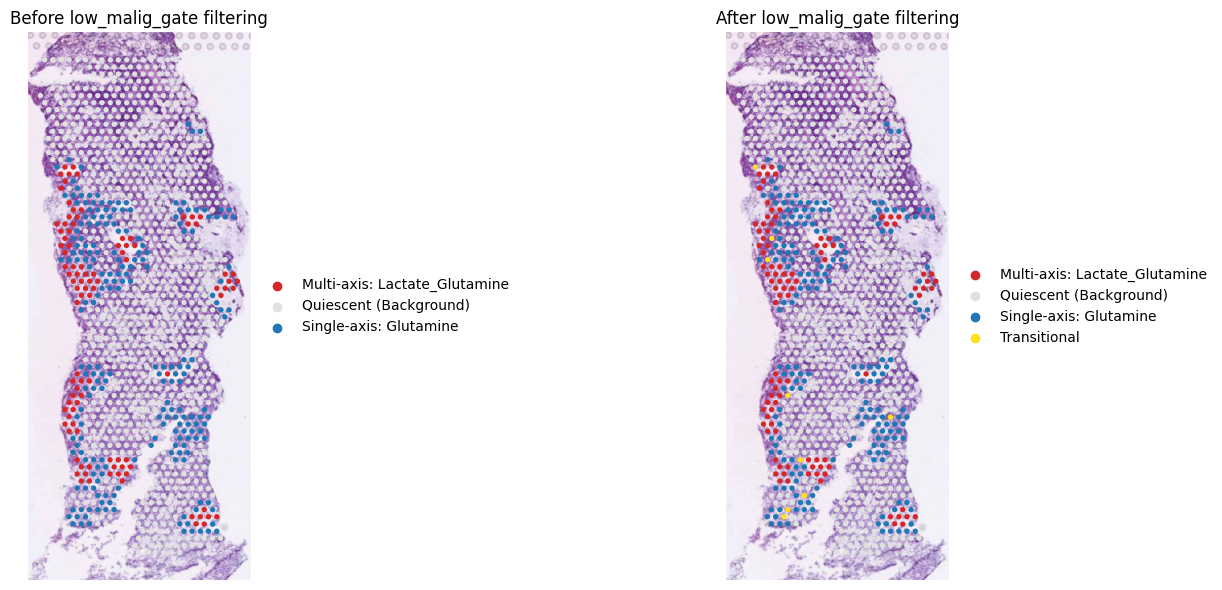

✅ 阶段二执行完毕！
当前 adata_model.obs 中保留了两个关键列：
   1. Niche_Annotation_PreFilter  -> 过滤前初始生态位
   2. Niche_Annotation            -> 经过 low_malig_gate 清洗后的最终生态位


In [12]:
# =========================================================
# Cell 7: 空间通讯加权分数计算与生态位标注 (阶段二)
# 新逻辑：
# 1. 先按代谢统计规则得到初始生态位
# 2. 再在 active niche 内部，逐个 spot 检查是否满足 low_malig_gate
# 3. 不满足的 spot 从生态位中移出，改成 Transitional
# 4. 如果某个生态位删掉太多，剩下的不再构成生态位，则整体取消
# =========================================================
import os
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import scanpy as sc
from sklearn.mixture import GaussianMixture
from IPython.display import display
from scipy.stats import hypergeom
from statsmodels.stats.multitest import multipletests

print("=== 阶段二: 代谢统计初判 + low_malig_gate spot级过滤版 ===")

# ---------------------------------------------------------
# Step 4.1: 构建空间感知的连续通讯分数 (Coupling Score)
# ---------------------------------------------------------
print("--> 1. 计算空间加权代谢通讯分数 (Coupling Score)...")
adj_matrix = adata_model.obsp["spatial_connectivities"]

for k in AXES:
    sender_scores = adata_model.obs[f"{k}_Sender_Score"].values
    receiver_scores = adata_model.obs[f"{k}_Receiver_Score"].values

    neighbor_receiver_sum = adj_matrix.dot(receiver_scores)
    raw_coupling = sender_scores * neighbor_receiver_sum

    coupling_score = np.log1p(raw_coupling)
    adata_model.obs[f"Coupling_{k}"] = coupling_score

# ---------------------------------------------------------
# Step 4.2: 自适应混合阈值算法 (GMM + 动态稳健兜底)
# ---------------------------------------------------------
print("--> 2. 学习每条代谢轴的自适应阈值 (GMM / Robust Dynamic)...")
thresholds_dict = {}

fig, axes = plt.subplots(len(AXES), 1, figsize=(8, 3.5 * len(AXES)))
if len(AXES) == 1:
    axes = [axes]

for idx, k in enumerate(AXES):
    scores = adata_model.obs[f"Coupling_{k}"].values
    scores_clean = scores[~np.isnan(scores) & (scores > 0)].reshape(-1, 1)

    t_high, t_quiet = None, None
    method_used = "Robust Dynamic Fallback"

    if len(scores_clean) > 50:
        try:
            gmm = GaussianMixture(n_components=2, random_state=42)
            labels = gmm.fit_predict(scores_clean)

            m0, m1 = gmm.means_[0][0], gmm.means_[1][0]
            s0 = np.sqrt(gmm.covariances_[0][0][0])
            s1 = np.sqrt(gmm.covariances_[1][0][0])

            if abs(m0 - m1) > 0.8 * np.std(scores_clean):
                if m0 > m1:
                    t_high = np.min(scores_clean[labels == 0])
                    t_quiet = m1 + s1
                else:
                    t_high = np.min(scores_clean[labels == 1])
                    t_quiet = m0 + s0
                method_used = "GMM (2-Components)"
        except Exception:
            pass

    if t_high is None:
        mean_val = np.mean(scores)
        std_val = np.std(scores)
        t_high_candidate_1 = mean_val + 1.5 * std_val
        t_high_candidate_2 = np.quantile(scores, 0.95)
        t_high = max(t_high_candidate_1, t_high_candidate_2)
        t_quiet = mean_val

    # 硬基线安全锁
    if t_high < 0.15:
        t_high = np.inf

    thresholds_dict[k] = {
        "T_high": t_high,
        "T_quiet": t_quiet,
        "Method": method_used
    }

    adata_model.obs[f"Active_{k}"] = (scores >= t_high).astype(int)
    adata_model.obs[f"Quiet_{k}"] = (scores <= t_quiet).astype(int)

    sns.kdeplot(scores, ax=axes[idx], fill=True, color="#4CB391", alpha=0.5, bw_adjust=0.5)
    axes[idx].axvline(t_high, color="red", linestyle="--", label=f"T_high (Active): {t_high:.3f}")
    axes[idx].axvline(t_quiet, color="blue", linestyle="--", label=f"T_quiet (Quiet): {t_quiet:.3f}")
    axes[idx].set_title(f"Axis: {k} | Score Distribution | Method: {method_used}")
    axes[idx].set_xlabel("Log1p(Coupling Score)")
    axes[idx].legend()

plt.tight_layout()
plt.show()

df_thresholds = pd.DataFrame(thresholds_dict).T
print("\n--- 自适应阈值计算结果 ---")
display(df_thresholds)

# ---------------------------------------------------------
# Step 4.3: 构建 low_malig_gate 的 spot 过滤标记
# 这里只做 spot 自身检查，不再做 cluster级 tumor support
# ---------------------------------------------------------
print("--> 2.5. 构建基于 low_malig_gate 的 spot 保留标记...")

possible_malig_cols = ["Malignant", "malignant", "Tumor", "tumor", "Cancer", "cancer"]
malig_col = None
for c in possible_malig_cols:
    if c in adata_model.obs.columns:
        malig_col = c
        break

if malig_col is None:
    raise KeyError("❌ 未找到 SpaCET 恶性分数字段，如 'Malignant'。")

# 读取 SpaCET GMM 阈值
gmm_csv = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET/GMM_Optimal_Threshold_Result.csv"
gmm_df = pd.read_csv(gmm_csv)

hard_tumor_threshold = float(
    gmm_df.loc[gmm_df["Metric"] == "Optimal_GMM_Threshold", "Value"].iloc[0]
)

# 你要求的规则：只看 low_malig_gate
low_malig_gate = max(0.0, hard_tumor_threshold - 0.20)

print(f"✅ malignant列: {malig_col}")
print(f"✅ hard_tumor_threshold = {hard_tumor_threshold:.4f}")
print(f"✅ low_malig_gate      = {low_malig_gate:.4f}")

malig_values = adata_model.obs[malig_col].astype(float).values
adata_model.obs["Keep_By_LowMalig"] = (malig_values >= low_malig_gate).astype(int)

# ---------------------------------------------------------
# Step 5: 先按代谢统计规则，得到“初始生态位”
# 此时还不做 low_malig_gate spot删除
# ---------------------------------------------------------
print("\n--> 3. 先按代谢统计规则，计算初始生态位...")

M_global = adata_model.n_obs
bg_active_counts = {k: int(adata_model.obs[f"Active_{k}"].sum()) for k in AXES}
bg_quiet_counts = {k: int(adata_model.obs[f"Quiet_{k}"].sum()) for k in AXES}

bg_active_fracs = {k: bg_active_counts[k] / M_global for k in AXES}
bg_quiet_fracs = {k: bg_quiet_counts[k] / M_global for k in AXES}

native_clusters = sorted(adata_model.obs[native_cluster_key].unique())
pvals_active_dict = {k: [] for k in AXES}
pvals_quiet_dict = {k: [] for k in AXES}

for k in AXES:
    adata_model.obs[f"{k}_Cluster_Active_Frac"] = 0.0

for c in native_clusters:
    c_mask = adata_model.obs[native_cluster_key] == c
    N_cluster = int(c_mask.sum())

    for k in AXES:
        k_obs_act = int(adata_model.obs.loc[c_mask, f"Active_{k}"].sum())
        k_obs_qui = int(adata_model.obs.loc[c_mask, f"Quiet_{k}"].sum())

        act_frac = k_obs_act / N_cluster if N_cluster > 0 else 0.0
        adata_model.obs.loc[c_mask, f"{k}_Cluster_Active_Frac"] = act_frac

        pval_a = hypergeom.sf(k_obs_act - 1, M_global, bg_active_counts[k], N_cluster) if k_obs_act > 0 else 1.0
        pval_q = hypergeom.sf(k_obs_qui - 1, M_global, bg_quiet_counts[k], N_cluster) if k_obs_qui > 0 else 1.0

        pvals_active_dict[k].append(pval_a)
        pvals_quiet_dict[k].append(pval_q)

fdr_active_dict = {}
fdr_quiet_dict = {}
for k in AXES:
    _, fdr_a, _, _ = multipletests(pvals_active_dict[k], method="fdr_bh")
    _, fdr_q, _, _ = multipletests(pvals_quiet_dict[k], method="fdr_bh")
    fdr_active_dict[k] = fdr_a
    fdr_quiet_dict[k] = fdr_q

# ==========================================
# 4. 初始生态位判定（过滤前）
# ==========================================
cluster_annotations = {}
cluster_stats = []

MIN_FC = 1.30
MIN_ACTIVE_SPOTS = 10
MIN_INTENSITY_RATIO = 1.20
QUIESCENT_COLD_AXIS_NUM = 6

global_mean_scores = {k: adata_model.obs[f"Coupling_{k}"].mean() for k in AXES}

for idx, c in enumerate(native_clusters):
    c_mask = adata_model.obs[native_cluster_key] == c
    N_cluster = int(c_mask.sum())

    sig_active_axes = []
    cold_axes = []

    stat_row = {
        "Cluster_ID": c,
        "Spot_Count": N_cluster
    }

    for k in AXES:
        act_frac = float(adata_model.obs.loc[c_mask, f"{k}_Cluster_Active_Frac"].iloc[0])
        qui_frac = float(adata_model.obs.loc[c_mask, f"Quiet_{k}"].sum() / N_cluster) if N_cluster > 0 else 0.0
        k_obs_act = int(adata_model.obs.loc[c_mask, f"Active_{k}"].sum())
        cluster_mean_score = float(adata_model.obs.loc[c_mask, f"Coupling_{k}"].mean())

        fc_act = act_frac / (bg_active_fracs[k] + 1e-9)
        fdr_a = float(fdr_active_dict[k][idx])
        intensity_ratio = cluster_mean_score / (global_mean_scores[k] + 1e-9)

        pass_ratio = fc_act >= MIN_FC
        pass_count = k_obs_act >= MIN_ACTIVE_SPOTS
        pass_intensity = intensity_ratio >= MIN_INTENSITY_RATIO
        pass_fdr = fdr_a < 0.05

        # 初始生态位只看代谢统计条件
        if pass_ratio and pass_count and pass_intensity and pass_fdr:
            sig_active_axes.append(k)

        if qui_frac > bg_quiet_fracs[k] or fc_act < 0.5:
            cold_axes.append(k)

        stat_row[f"{k}_Act_Frac"] = round(act_frac, 3)
        stat_row[f"{k}_FC_Act"] = round(fc_act, 2)
        stat_row[f"{k}_FDR_Act"] = f"{fdr_a:.2e}"
        stat_row[f"{k}_Intensity_Ratio"] = round(intensity_ratio, 2)
        stat_row[f"{k}_Pass_All"] = int(pass_ratio and pass_count and pass_intensity and pass_fdr)

    if len(sig_active_axes) == 0 and len(cold_axes) >= QUIESCENT_COLD_AXIS_NUM:
        c_label = "Quiescent (Background)"
    elif len(sig_active_axes) == 1:
        c_label = f"Single-axis: {sig_active_axes[0]}"
    elif len(sig_active_axes) >= 2:
        c_label = f"Multi-axis: {'_'.join(sig_active_axes)}"
    else:
        c_label = "Transitional"

    cluster_annotations[c] = c_label
    stat_row["Sig_Active_Axes"] = ",".join(sig_active_axes) if len(sig_active_axes) > 0 else "None"
    stat_row["Cold_Axis_Count"] = len(cold_axes)
    stat_row["Initial_Label"] = c_label
    cluster_stats.append(stat_row)

# 先保存“过滤前”的初始生态位
adata_model.obs["Niche_Annotation_PreFilter"] = (
    adata_model.obs[native_cluster_key].map(cluster_annotations).astype(str)
)

df_cluster_stats = pd.DataFrame(cluster_stats).set_index("Cluster_ID")
print("\n--- 基于超几何富集 + 统计约束的初始生态位判定表（过滤前）---")
display(df_cluster_stats)

# ---------------------------------------------------------
# Step 5.5: spot级别 low_malig_gate 过滤
# 规则：
# 1. 只检查 Single-axis / Multi-axis 这两类 active niche
# 2. 不满足 low_malig_gate 的 spot，移出生态位，改成 Transitional
# 3. 如果一个生态位删掉太多，剩下太少，就整个取消
# ---------------------------------------------------------
print("\n--> 3.5. 执行 spot 级 low_malig_gate 过滤...")

# 从过滤前标签复制出过滤后标签
adata_model.obs["Niche_Annotation"] = adata_model.obs["Niche_Annotation_PreFilter"].astype(str)

# 只对 active niche 做过滤
is_active_niche = (
    adata_model.obs["Niche_Annotation"].str.startswith("Single-axis:") |
    adata_model.obs["Niche_Annotation"].str.startswith("Multi-axis:")
)

# 在 active niche 中，不满足 low_malig_gate 的 spot -> 改成 Transitional
bad_spot_mask = is_active_niche & (adata_model.obs["Keep_By_LowMalig"] == 0)
adata_model.obs.loc[bad_spot_mask, "Niche_Annotation"] = "Transitional"

# 再检查：某个生态位如果删掉太多，则整体取消
MIN_REMAIN_SPOTS_AFTER_FILTER = 10
MIN_REMAIN_FRAC_AFTER_FILTER = 0.50

filter_summary = []

for c in native_clusters:
    c_mask = adata_model.obs[native_cluster_key] == c

    pre_labels = adata_model.obs.loc[c_mask, "Niche_Annotation_PreFilter"].unique().tolist()
    active_pre_labels = [
        x for x in pre_labels
        if str(x).startswith("Single-axis:") or str(x).startswith("Multi-axis:")
    ]

    for label in active_pre_labels:
        original_mask = c_mask & (adata_model.obs["Niche_Annotation_PreFilter"] == label)
        remain_mask = c_mask & (adata_model.obs["Niche_Annotation"] == label)

        original_n = int(original_mask.sum())
        remain_n = int(remain_mask.sum())
        removed_n = original_n - remain_n
        remain_frac = remain_n / original_n if original_n > 0 else 0.0

        drop_whole_niche = (
            (remain_n < MIN_REMAIN_SPOTS_AFTER_FILTER) or
            (remain_frac < MIN_REMAIN_FRAC_AFTER_FILTER)
        )

        if drop_whole_niche:
            adata_model.obs.loc[original_mask, "Niche_Annotation"] = "Transitional"

        filter_summary.append({
            "Cluster_ID": c,
            "Original_Niche": label,
            "Original_Spots": original_n,
            "Remain_Spots": remain_n,
            "Removed_Spots": removed_n,
            "Remain_Fraction": round(remain_frac, 3),
            "Drop_Whole_Niche": int(drop_whole_niche)
        })

# 转回 category
adata_model.obs["Niche_Annotation"] = adata_model.obs["Niche_Annotation"].astype("category")

df_filter_summary = pd.DataFrame(filter_summary)
print("\n--- low_malig_gate 过滤汇总表 ---")
display(df_filter_summary)

print("✅ spot级 low_malig_gate 过滤完成。")
print("✅ 不满足 low_malig_gate 的 active niche spot 已移出。")
print("✅ 删除过多、不再构成生态位的区域，已整体改为 Transitional。")

# ---------------------------------------------------------
# 可视化: 过滤前 / 过滤后 对比
# ---------------------------------------------------------
print("\n--> 4. 绘制过滤前后生态位对比图...")

color_list = [
    "#d62728", "#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd",
    "#8c564b", "#e377c2", "#7f7f7f", "#bcbd22", "#17becf",
    "#ff9896", "#aec7e8", "#98df8a", "#ffbb78", "#c5b0d5",
    "#c49c94", "#f7b6d2", "#c7c7c7", "#dbdb8d", "#9edae5"
]

def build_palette(categories):
    palette = {}
    color_idx = 0
    for cat in categories:
        cat = str(cat)
        if "Quiescent" in cat:
            palette[cat] = "#e0e0e0"
        elif "Transitional" in cat:
            palette[cat] = "#ffe119"
        else:
            palette[cat] = color_list[color_idx % len(color_list)]
            color_idx += 1
    return palette

pre_categories = pd.Series(adata_model.obs["Niche_Annotation_PreFilter"].astype(str)).unique().tolist()
post_categories = adata_model.obs["Niche_Annotation"].astype(str).unique().tolist()

pre_palette = build_palette(pre_categories)
post_palette = build_palette(post_categories)

fig, axs = plt.subplots(1, 2, figsize=(16, 6))

sc.pl.spatial(
    adata_model,
    color="Niche_Annotation_PreFilter",
    size=1,
    title="Before low_malig_gate filtering",
    frameon=False,
    palette=pre_palette,
    ax=axs[0],
    show=False
)

sc.pl.spatial(
    adata_model,
    color="Niche_Annotation",
    size=1,
    title="After low_malig_gate filtering",
    frameon=False,
    palette=post_palette,
    ax=axs[1],
    show=False
)

plt.tight_layout()
plt.show()

print("✅ 阶段二执行完毕！")
print("当前 adata_model.obs 中保留了两个关键列：")
print("   1. Niche_Annotation_PreFilter  -> 过滤前初始生态位")
print("   2. Niche_Annotation            -> 经过 low_malig_gate 清洗后的最终生态位")

可视化每个代谢轴的空间代谢通讯潜力图


=== 附加分析: 生成十种代谢物空间代谢通讯潜力图 ===


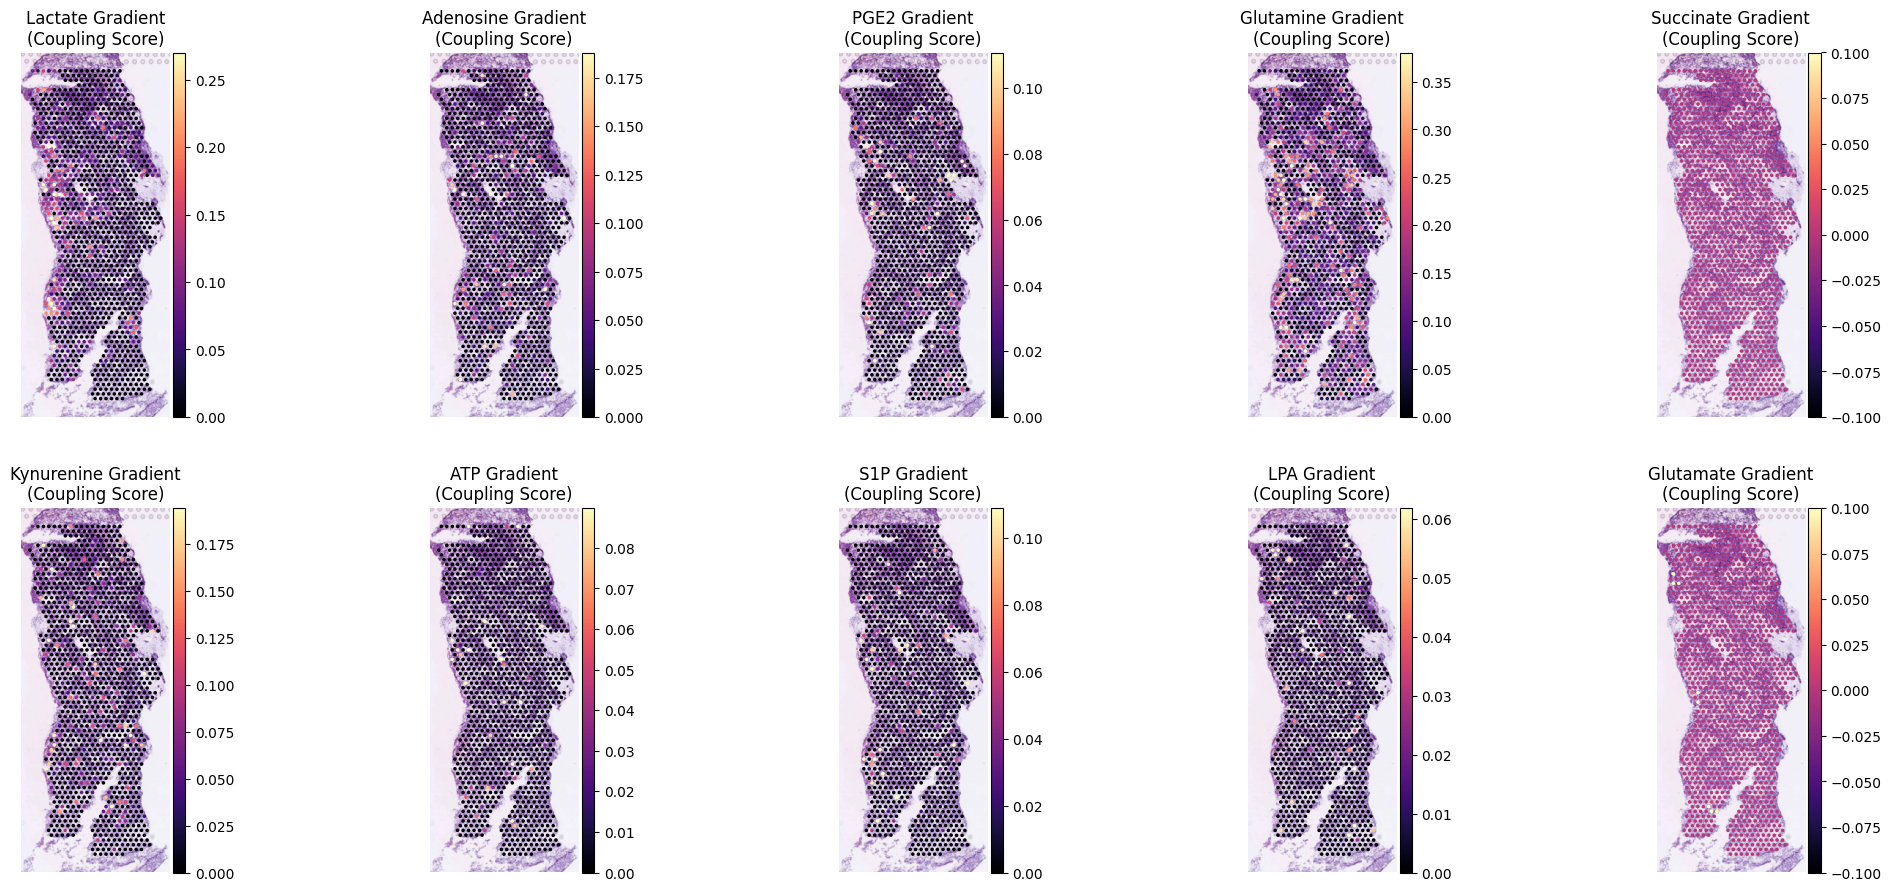

✅ 10 种代谢物的空间代谢通讯潜力图绘制完毕！
📁 图片已保存至：/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My/10种代谢物的空间代谢通讯潜力图.png


In [13]:
# =========================================================
# Cell 8: 绘制 10 种代谢物的空间代谢通讯潜力图
# =========================================================
import os
import matplotlib.pyplot as plt
import scanpy as sc

print("=== 附加分析: 生成十种代谢物空间代谢通讯潜力图 ===")

gradient_columns = [f"Coupling_{k}" for k in AXES]
plot_titles = [f"{k} Gradient\n(Coupling Score)" for k in AXES]

sc.pl.spatial(
    adata_model, color=gradient_columns, cmap="magma", size=1, ncols=5, 
    frameon=False, title=plot_titles, vmin=0, vmax='p99', show=False
)

plt.subplots_adjust(wspace=0.1, hspace=0.2)
plt.gcf().set_size_inches(25, 10)

# ===================== 新增：保存图片（按你的要求）=====================
# 定义保存路径（完全按照你指定的路径）
save_path = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My"
# 确保文件夹存在（不存在自动创建）
os.makedirs(save_path, exist_ok=True)
# 保存文件名 + 完整路径
save_full_path = os.path.join(save_path, "10种代谢物的空间代谢通讯潜力图.png")

# 保存图片（高清、无截断）
plt.savefig(
    save_full_path,
    dpi=300,          # 高清分辨率
    bbox_inches="tight",  # 防止标题/图例被截断
    pad_inches=0.1
)
# ====================================================================

plt.show()

print(f"✅ 10 种代谢物的空间代谢通讯潜力图绘制完毕！")
print(f"📁 图片已保存至：{save_full_path}")

阶段三  空间拓扑图剪枝与重塑 (Spatial Refinement: Split, Merge & Smooth)


--> 4. 规范化命名并绘制最终 TMCN 地图...
✅ Final_Niche_Type 已生成
当前类别： ['Multi_Axis_Lactate_Glutamine', 'TMCN_Glutamine_Axis', 'TMCN_Quiescent', 'TMCN_Transitional']


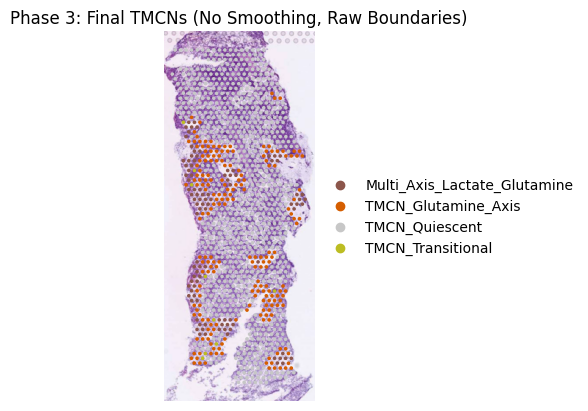

✅ 阶段三执行完毕！结果保存至: /home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My/SN124_A551763_Rep2_NicheCompassAndmy_Final.h5ad


In [14]:
# =========================================================
# Cell 9：名称规范化（不平滑、不改边界）
# =========================================================
print("\n--> 4. 规范化命名并绘制最终 TMCN 地图...")

import os
import scanpy as sc
import seaborn as sns

# 如果之前有旧列，先删掉，避免历史结果污染
if "Final_Niche_Type" in adata_model.obs.columns:
    adata_model.obs.drop(columns=["Final_Niche_Type"], inplace=True)

def map_niche_name(raw_name):
    raw_name = str(raw_name)

    if raw_name.startswith("Single-axis:"):
        axis = raw_name.split(": ")[1].strip()
        return f"TMCN_{axis}_Axis"

    elif raw_name.startswith("Multi-axis:"):
        axes_str = raw_name.split(": ")[1].strip()
        return f"Multi_Axis_{axes_str}"

    elif raw_name.startswith("Quiescent"):
        return "TMCN_Quiescent"

    else:
        return "TMCN_Transitional"

# 用 Cell 7 的输出生成 Final_Niche_Type
adata_model.obs["Final_Niche_Type"] = (
    adata_model.obs["Niche_Annotation"]
    .astype(str)
    .apply(map_niche_name)
    .astype("category")
)

print("✅ Final_Niche_Type 已生成")
print("当前类别：", adata_model.obs["Final_Niche_Type"].cat.categories.tolist())

# 配色
base_palette = {
    "TMCN_Quiescent": "#c7c7c7",
    "TMCN_Transitional": "#bcbd22"
}

single_axis_colors = sns.color_palette("colorblind", n_colors=len(AXES)).as_hex()
single_axis_palette = {
    f"TMCN_{axis}_Axis": single_axis_colors[i % len(single_axis_colors)]
    for i, axis in enumerate(AXES)
}

multi_colors = ["#8c564b", "#8b008b", "#008080", "#ff1493",
                "#000080", "#ff8c00", "#4682b4", "#556b2f"]

active_palette = {}
c_idx = 0

for cat in adata_model.obs["Final_Niche_Type"].cat.categories:
    if cat in single_axis_palette:
        active_palette[cat] = single_axis_palette[cat]
    elif cat in base_palette:
        active_palette[cat] = base_palette[cat]
    elif "Multi_Axis" in cat:
        active_palette[cat] = multi_colors[c_idx % len(multi_colors)]
        c_idx += 1
    else:
        active_palette[cat] = "#9467bd"

sc.pl.spatial(
    adata_model,
    color="Final_Niche_Type",
    size=1,
    title="Phase 3: Final TMCNs (No Smoothing, Raw Boundaries)",
    frameon=False,
    palette=active_palette,
    legend_loc="right margin",
    show=True
)

save_dir = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My"
os.makedirs(save_dir, exist_ok=True)
adata_save_path = os.path.join(save_dir, "SN124_A551763_Rep2_NicheCompassAndmy_Final.h5ad")
adata_model.write(adata_save_path)

print(f"✅ 阶段三执行完毕！结果保存至: {adata_save_path}")

结合SpaCET和我的结果
我现在有了我自己计算的Final_Niche_Type标签的结果和SpaCET得出的肿瘤非肿瘤区域划分标签结果，现在要把他们两个结合一下。
1、将SpaCET的Predicted_Tumor标签结果和我的非TMCN_Quiescent结果全都保留，合并到一起，这是一个肿瘤区域，其余区域，也就是将将SpaCET的Predicted_Non_Tumor标签结果和我的TMCN_Quiescent结果合并到一起形成一个Healthy非肿瘤区域。

2、在肿瘤区域中，将我的Final_Niche_Type标签中是单个代谢轴或者多个代谢轴的区域还是各自单独一个肿瘤标签（还是使用我的Final_Niche_Type标签的结果），将SpaCET的Predicted_Tumor标签结果和我得出的TMCN_Quiescent结果视作TMCN_Quiescent区域。

=== 阶段四: 最终层级生态位构建 + 病理二分类对照图 ===
--> 1. 正在加载 NicheCompass + TMCN 结果...


✅ 数据加载成功: 1162 spots, 3033 genes
--> 2. 正在读取并合并 SpaCET GMM 预测标签...
✅ 成功导入 SpaCET GMM 预测标签列: Unsupervised_Pred_0.53
--> 3. 正在按照 ARI 计算策略生成病理 Tumor / Non-Tumor 二分类标签...
✅ 病理二分类标签生成完成，类别统计如下：
Pathology_Tumor        1133
Unmapped_for_ARI         29
Pathology_Non_Tumor       0
Name: Pathology_Binary_ARI, dtype: int64
--> 4. 正在执行 SpaCET + TMCN 层级生态位整合逻辑...
✅ Level1_Macro_Region 与 Level2_Micro_Niche 已生成。

Level1_Macro_Region 统计：
Healthy_Region    702
Tumor_Region      460
Name: Level1_Macro_Region, dtype: int64

Level2_Micro_Niche 统计：
Healthy_Region                  702
TMCN_Glutamine_Axis             204
TMCN_Quiescent                  157
Multi_Axis_Lactate_Glutamine     99
Name: Level2_Micro_Niche, dtype: int64
--> 5. 正在绘制病理二分类 vs 最终生态位对照图...


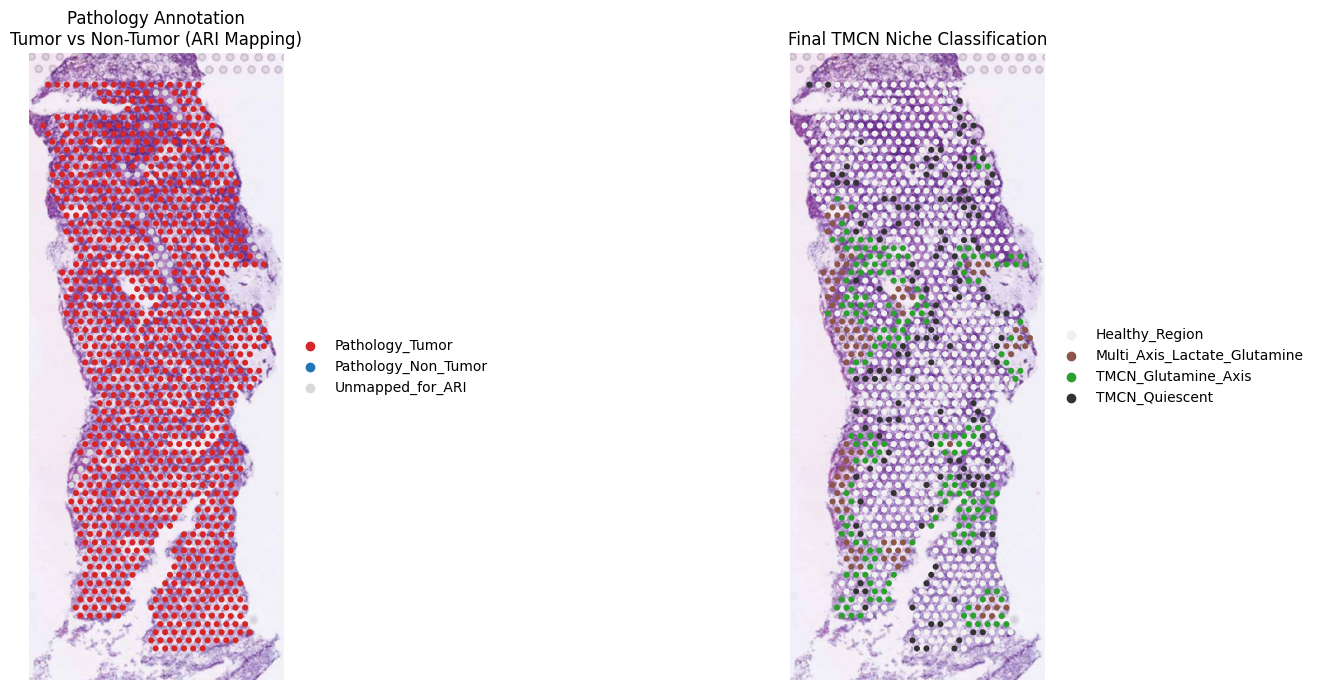

✅ 两联对照图已保存至：/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My/Pathology_TumorNonTumor_vs_Final_TMCN_Niche.png
--> 6. 正在计算最终详细生态位的代谢轴高活性 Spot 比例...
✅ 各代谢轴高活性比例已保存至：/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My/Level2_Micro_Niche_Active_Fractions.csv
--> 7. 正在精简 adata.obs 冗余中间特征...
✅ 精简完成，共移除 65 个中间列。
当前保留的关键结果列包括：
  - pathology_annotation
  - Pathology_Binary_ARI
  - Level1_Macro_Region
  - Level2_Micro_Niche

🎉 Cell 10 执行完成！
✅ 最终 h5ad 已覆盖保存至：/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My/SN124_A551763_Rep2_NicheCompassAndmy_Final.h5ad
✅ 病理二分类 vs 最终生态位对照图已保存至：/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My/Pathology_TumorNonTumor_vs_Final_TMCN_Niche.png
📌 本 Cell 10 只生成一个两联图：
  左图：病理注释 Tumor / Non-Tumor，严格按照 ARI 映射规则
  右图：你的最终 Level2_Micro_Niche 生

In [15]:
# =========================================================
# Cell 10: 最终层级生态位构建 + 病理二分类 vs 最终生态位对照图
# 目标：
# 1. 按 SpaCET + Final_Niche_Type 生成 Level1_Macro_Region 和 Level2_Micro_Niche
# 2. 严格按照 ARI 计算时的病理映射规则生成 Pathology_Binary_ARI
# 3. 只绘制两个图：
#    左图：病理注释 Tumor / Non-Tumor 二分类
#    右图：你的最终生态位划分结果 Level2_Micro_Niche
# =========================================================

import anndata as ad
import pandas as pd
import numpy as np
import scanpy as sc
import matplotlib.pyplot as plt
import os

print("=== 阶段四: 最终层级生态位构建 + 病理二分类对照图 ===")

# ==========================================
# 1. 路径配置
# ==========================================
path_h5ad_niche = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My/SN124_A551763_Rep2_NicheCompassAndmy_Final.h5ad"

path_spacet_csv = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET/GMM_Tumor_NonTumor_Pred_Labels.csv"

SAVE_DIR = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My"
os.makedirs(SAVE_DIR, exist_ok=True)

print("--> 1. 正在加载 NicheCompass + TMCN 结果...")
adata = ad.read_h5ad(path_h5ad_niche)

print(f"✅ 数据加载成功: {adata.n_obs} spots, {adata.n_vars} genes")

# ==========================================
# 2. 检查关键列
# ==========================================
required_cols = ["pathology_annotation", "Final_Niche_Type"]

for col in required_cols:
    if col not in adata.obs.columns:
        raise KeyError(
            f"❌ 缺少关键列: {col}\n"
            f"当前 adata.obs.columns 为:\n{adata.obs.columns.tolist()}"
        )

# ==========================================
# 3. 读取并合并 SpaCET GMM 预测标签
# ==========================================
print("--> 2. 正在读取并合并 SpaCET GMM 预测标签...")

spacet_df = pd.read_csv(path_spacet_csv, index_col=0)

spacet_pred_cols = [c for c in spacet_df.columns if c.startswith("Unsupervised_Pred_")]

if len(spacet_pred_cols) == 0:
    raise KeyError(
        "❌ 在 SpaCET GMM 预测 CSV 中没有找到以 'Unsupervised_Pred_' 开头的列。"
    )

spacet_pred_col = spacet_pred_cols[0]

# 防止重复运行 Cell 10 时 join 报错
if spacet_pred_col in adata.obs.columns:
    print(f"⚠️ 检测到 adata.obs 中已存在 {spacet_pred_col}，将先删除旧列后重新合并。")
    adata.obs.drop(columns=[spacet_pred_col], inplace=True)

adata.obs = adata.obs.join(spacet_df[[spacet_pred_col]], how="left")

if adata.obs[spacet_pred_col].isna().sum() > 0:
    print(
        f"⚠️ 警告：{adata.obs[spacet_pred_col].isna().sum()} 个 spots 没有匹配到 SpaCET GMM 预测标签。"
    )

print(f"✅ 成功导入 SpaCET GMM 预测标签列: {spacet_pred_col}")

# ==========================================
# 4. 严格按照 ARI 计算策略生成病理二分类标签
# ==========================================
print("--> 3. 正在按照 ARI 计算策略生成病理 Tumor / Non-Tumor 二分类标签...")

# 这个映射必须与 Cell 11 计算 ARI 时保持一致
gt_map_int = {
    "tumor": 1,
    "tumor&stroma_IC med to high": 1,
    "stroma_fibroblastic_IC high": 1,

    "epithelium&submucosa": 0,
    "non neo epithelium": 0,
    "submucosa": 0,
    "IC aggregregate_submucosa": 0,

    # 兼容可能的正确拼写，防止不同数据集写法不一致
    "IC aggregate_submucosa": 0,
    "IC aggregate connective tissue": 0
}

gt_map_str = {
    1: "Pathology_Tumor",
    0: "Pathology_Non_Tumor"
}

patho_clean = adata.obs["pathology_annotation"].astype(str).str.strip()
pathology_numeric = patho_clean.map(gt_map_int)

adata.obs["Pathology_Binary_ARI"] = pathology_numeric.map(gt_map_str)

# 没有进入 ARI 映射规则的 spot，不强行划为 Tumor 或 Non-Tumor
adata.obs["Pathology_Binary_ARI"] = adata.obs["Pathology_Binary_ARI"].fillna("Unmapped_for_ARI")
adata.obs["Pathology_Binary_ARI"] = pd.Categorical(
    adata.obs["Pathology_Binary_ARI"],
    categories=[
        "Pathology_Tumor",
        "Pathology_Non_Tumor",
        "Unmapped_for_ARI"
    ],
    ordered=False
)

print("✅ 病理二分类标签生成完成，类别统计如下：")
print(adata.obs["Pathology_Binary_ARI"].value_counts())

# ==========================================
# 5. 生成最终 Level1 / Level2 层级生态位
# ==========================================
print("--> 4. 正在执行 SpaCET + TMCN 层级生态位整合逻辑...")

# 初始化
adata.obs["Level1_Macro_Region"] = "Healthy_Region"
adata.obs["Level2_Micro_Niche"] = "Healthy_Region"

# 关键判断条件
is_spacet_tumor = adata.obs[spacet_pred_col].astype(str) == "Predicted_Tumor"

final_niche_str = adata.obs["Final_Niche_Type"].astype(str)

is_niche_quiescent = final_niche_str == "TMCN_Quiescent"
is_niche_transitional = final_niche_str == "TMCN_Transitional"
is_quiescent_or_transitional = is_niche_quiescent | is_niche_transitional

# ----------------- Level 1: 宏观 Tumor / Healthy -----------------
# SpaCET 预测为 Tumor
# OR
# TMCN 不是 Quiescent 且不是 Transitional
# => Tumor_Region
tumor_mask = is_spacet_tumor | (~is_quiescent_or_transitional)

adata.obs.loc[tumor_mask, "Level1_Macro_Region"] = "Tumor_Region"
adata.obs["Level1_Macro_Region"] = adata.obs["Level1_Macro_Region"].astype("category")

# ----------------- Level 2: 最终详细生态位 -----------------
# 1. 真正活跃的 TMCN 生态位直接保留
active_niche_mask = ~is_quiescent_or_transitional
adata.obs.loc[active_niche_mask, "Level2_Micro_Niche"] = final_niche_str[active_niche_mask]

# 2. SpaCET 判为 Tumor 但 TMCN 是 Quiescent / Transitional
#    统一视作肿瘤内部代谢休眠 / 耗竭生态位
target_tumor_quiescent_mask = is_spacet_tumor & is_quiescent_or_transitional
adata.obs.loc[target_tumor_quiescent_mask, "Level2_Micro_Niche"] = "TMCN_Quiescent"

adata.obs["Level2_Micro_Niche"] = adata.obs["Level2_Micro_Niche"].astype("category")

print("✅ Level1_Macro_Region 与 Level2_Micro_Niche 已生成。")
print("\nLevel1_Macro_Region 统计：")
print(adata.obs["Level1_Macro_Region"].value_counts())

print("\nLevel2_Micro_Niche 统计：")
print(adata.obs["Level2_Micro_Niche"].value_counts())

# ==========================================
# 6. 只绘制两个图：病理二分类 vs 最终生态位
# ==========================================
print("--> 5. 正在绘制病理二分类 vs 最终生态位对照图...")

# 病理二分类配色
pathology_palette = {
    "Pathology_Tumor": "#d62728",
    "Pathology_Non_Tumor": "#1f77b4",
    "Unmapped_for_ARI": "#d9d9d9"
}

# 最终生态位配色
base_micro_palette = {
    "TMCN_Lactate_Axis": "#d62728",
    "TMCN_Adenosine_Axis": "#1f77b4",
    "TMCN_PGE2_Axis": "#ff7f0e",
    "TMCN_Glutamine_Axis": "#2ca02c",
    "TMCN_Succinate_Axis": "#9467bd",
    "TMCN_Kynurenine_Axis": "#e377c2",
    "TMCN_ATP_Axis": "#17becf",
    "TMCN_S1P_Axis": "#7f7f7f",
    "TMCN_LPA_Axis": "#ff9896",
    "TMCN_Glutamate_Axis": "#fada5e",
    "TMCN_Transitional": "#bcbd22",
    "TMCN_Quiescent": "#333333",
    "Healthy_Region": "#f0f0f0"
}

multi_axis_colors = [
    "#8c564b", "#8b008b", "#008080", "#ff1493",
    "#000080", "#ff8c00", "#4682b4", "#556b2f",
    "#a65628", "#984ea3", "#4daf4a", "#377eb8"
]

active_micro_colors = {}
multi_idx = 0

for cat in adata.obs["Level2_Micro_Niche"].cat.categories:
    cat_str = str(cat)

    if cat_str in base_micro_palette:
        active_micro_colors[cat_str] = base_micro_palette[cat_str]
    elif cat_str.startswith("Multi_Axis"):
        active_micro_colors[cat_str] = multi_axis_colors[multi_idx % len(multi_axis_colors)]
        multi_idx += 1
    else:
        active_micro_colors[cat_str] = "#000000"

fig, axs = plt.subplots(1, 2, figsize=(18, 7))

sc.pl.spatial(
    adata,
    color="Pathology_Binary_ARI",
    size=1,
    title="Pathology Annotation\nTumor vs Non-Tumor (ARI Mapping)",
    palette=pathology_palette,
    frameon=False,
    legend_loc="right margin",
    ax=axs[0],
    show=False
)

sc.pl.spatial(
    adata,
    color="Level2_Micro_Niche",
    size=1,
    title="Final TMCN Niche Classification",
    palette=active_micro_colors,
    frameon=False,
    legend_loc="right margin",
    ax=axs[1],
    show=False
)

plt.tight_layout()

comparison_fig_path = os.path.join(
    SAVE_DIR,
    "Pathology_TumorNonTumor_vs_Final_TMCN_Niche.png"
)

plt.savefig(
    comparison_fig_path,
    dpi=300,
    bbox_inches="tight",
    pad_inches=0.1
)

plt.show()

print(f"✅ 两联对照图已保存至：{comparison_fig_path}")

# ==========================================
# 7. 提取并保存：最终详细生态位各代谢轴高活性比例
# ==========================================
print("--> 6. 正在计算最终详细生态位的代谢轴高活性 Spot 比例...")

axes_active_cols = [c for c in adata.obs.columns if c.startswith("Active_")]

if len(axes_active_cols) > 0:
    active_frac_df = (
        adata.obs
        .groupby("Level2_Micro_Niche", observed=False)[axes_active_cols]
        .mean()
        .reset_index()
    )

    rename_map = {c: c.replace("Active_", "active_fraction_") for c in axes_active_cols}
    active_frac_df.rename(columns=rename_map, inplace=True)
    active_frac_df.rename(columns={"Level2_Micro_Niche": "Micro_Niche_Cluster"}, inplace=True)

    fraction_csv_path = os.path.join(SAVE_DIR, "Level2_Micro_Niche_Active_Fractions.csv")
    active_frac_df.to_csv(fraction_csv_path, index=False, encoding="utf-8-sig")

    print(f"✅ 各代谢轴高活性比例已保存至：{fraction_csv_path}")
else:
    print("⚠️ 未检测到 Active_ 开头的代谢轴活性列，跳过 active fraction 统计。")

# ==========================================
# 8. 精简 h5ad 文件，只保留核心结果列
# ==========================================
print("--> 7. 正在精简 adata.obs 冗余中间特征...")

drop_keywords = [
    "Sender_Score",
    "Receiver_Score",
    "Coupling_",
    "Active_",
    "Quiet_",
    "Cluster_Active_Frac",
    "nichecompass_",
    "latent_leiden",
    "Pred_Threshold_",
    "Unsupervised_Pred_",
    "Niche_Annotation",
    "Niche_Type",
    "Final_Niche_Type",
    "Ground_Truth"
]

cols_to_drop = []

for c in adata.obs.columns:
    if any(k in c for k in drop_keywords):
        cols_to_drop.append(c)

adata.obs.drop(columns=cols_to_drop, inplace=True, errors="ignore")

print(f"✅ 精简完成，共移除 {len(cols_to_drop)} 个中间列。")
print("当前保留的关键结果列包括：")
print("  - pathology_annotation")
print("  - Pathology_Binary_ARI")
print("  - Level1_Macro_Region")
print("  - Level2_Micro_Niche")

# ==========================================
# 9. 覆盖保存最终 h5ad
# ==========================================
adata.write_h5ad(path_h5ad_niche)

print("\n🎉 Cell 10 执行完成！")
print(f"✅ 最终 h5ad 已覆盖保存至：{path_h5ad_niche}")
print(f"✅ 病理二分类 vs 最终生态位对照图已保存至：{comparison_fig_path}")
print("======================================================")
print("📌 本 Cell 10 只生成一个两联图：")
print("  左图：病理注释 Tumor / Non-Tumor，严格按照 ARI 映射规则")
print("  右图：你的最终 Level2_Micro_Niche 生态位划分结果")
print("======================================================")

计算ARI

In [16]:
# =========================================================
# Cell 11: 空间多维全栈指标综合评估
# 新增:
# NMI, AMI, Homogeneity, Completeness, V-measure, Spatial Consistency Score
# 不计算 Spatial Permutation Decay Rate
# =========================================================

import scanpy as sc
import squidpy as sq
import pandas as pd
import numpy as np
import os
import warnings
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score,
    adjusted_mutual_info_score,
    homogeneity_score,
    completeness_score,
    v_measure_score,
    f1_score,
    silhouette_score,
    silhouette_samples,
    davies_bouldin_score
)

warnings.filterwarnings("ignore")

print("=" * 60)
print("🚀 开始执行全维度空间与特征指标综合评估...")
print("=" * 60)

# =========================================================
# 1. 加载数据
# =========================================================
path_h5ad = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/colorectal_12_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My/SN124_A551763_Rep2_NicheCompassAndmy_Final.h5ad"
adata = sc.read_h5ad(path_h5ad)

# =========================================================
# 工具函数
# =========================================================
def safe_silhouette_score(X, labels):
    labels = np.asarray(labels).astype(str)
    valid = pd.Series(labels).notna().values
    X = X[valid]
    labels = labels[valid]
    vc = pd.Series(labels).value_counts()
    keep_classes = vc[vc >= 2].index
    keep_mask = np.isin(labels, keep_classes)
    X = X[keep_mask]
    labels = labels[keep_mask]
    if len(np.unique(labels)) < 2 or X.shape[0] <= len(np.unique(labels)):
        return np.nan, None, keep_mask
    sample_vals = silhouette_samples(X, labels)
    return float(np.mean(sample_vals)), sample_vals, keep_mask

def safe_davies_bouldin_score(X, labels):
    labels = np.asarray(labels).astype(str)
    vc = pd.Series(labels).value_counts()
    keep_classes = vc[vc >= 2].index
    keep_mask = np.isin(labels, keep_classes)
    X = X[keep_mask]
    labels = labels[keep_mask]
    if len(np.unique(labels)) < 2:
        return np.nan
    return float(davies_bouldin_score(X, labels))

def calculate_spatial_consistency(adata_obj, label_col="Level2_Micro_Niche"):
    if "spatial_connectivities" not in adata_obj.obsp:
        print("  --> 未检测到 spatial_connectivities，正在重构空间邻接图...")
        sq.gr.spatial_neighbors(
            adata_obj,
            coord_type="generic",
            spatial_key="spatial",
            n_neighs=8
        )

    conn = adata_obj.obsp["spatial_connectivities"].tocsr()
    labels = adata_obj.obs[label_col].astype(str).values

    same_neighbor_fracs = []

    for i in range(conn.shape[0]):
        start = conn.indptr[i]
        end = conn.indptr[i + 1]
        neigh_idx = conn.indices[start:end]

        if len(neigh_idx) == 0:
            continue

        same_frac = np.mean(labels[neigh_idx] == labels[i])
        same_neighbor_fracs.append(same_frac)

    if len(same_neighbor_fracs) == 0:
        return np.nan

    return float(np.mean(same_neighbor_fracs))

# =========================================================
# 模块一：宏观边界评估
# =========================================================
print("\n🟢 [1/4] 正在计算宏观监督指标 Level1_Macro_Region vs Ground Truth...")

gt_map = {
   'tumor': 1, 'tumor&stroma_IC med to high': 1, 
   'stroma_fibroblastic_IC med': 0, 'stroma_fibroblastic_IC high': 0
}

pred_map = {
    "Healthy_Region": 0,
    "Tumor_Region": 1
}

gt_raw = adata.obs["pathology_annotation"].astype(str).str.strip().map(gt_map).astype(float).values
pred_raw = adata.obs["Level1_Macro_Region"].astype(str).map(pred_map).astype(float).values

valid_mask = (~np.isnan(gt_raw)) & (~np.isnan(pred_raw))
y_true = gt_raw[valid_mask]
y_pred = pred_raw[valid_mask]

if len(y_true) == 0:
    raise ValueError("❌ 未发现有效 Spot，请检查 pathology_annotation 与 gt_map 是否匹配。")

print(f"  --> 参与宏观评估的有效 Spot 数量: {len(y_true)}")
print(f"  --> 病理 Tumor 数量: {int(np.sum(y_true == 1))}")
print(f"  --> 病理 Non-Tumor 数量: {int(np.sum(y_true == 0))}")

ari_val = adjusted_rand_score(y_true, y_pred)
f1_val = f1_score(y_true, y_pred, pos_label=1.0, average="binary")

nmi_val = normalized_mutual_info_score(y_true, y_pred)
ami_val = adjusted_mutual_info_score(y_true, y_pred)
homogeneity_val = homogeneity_score(y_true, y_pred)
completeness_val = completeness_score(y_true, y_pred)
v_measure_val = v_measure_score(y_true, y_pred)

print(f"  --> Adjusted Rand Index (ARI): {ari_val:.4f}")
print(f"  --> F1-Score: {f1_val:.4f}")
print(f"  --> Normalized Mutual Information (NMI): {nmi_val:.4f}")
print(f"  --> Adjusted Mutual Information (AMI): {ami_val:.4f}")
print(f"  --> Homogeneity Score: {homogeneity_val:.4f}")
print(f"  --> Completeness Score: {completeness_val:.4f}")
print(f"  --> V-measure Score: {v_measure_val:.4f}")

# =========================================================
# 模块二：微观特征纯度评估
# =========================================================
print("\n🔵 [2/4] 正在计算微观特征纯度指标 Level2_Micro_Niche...")

if "nichecompass_latent" in adata.obsm:
    X_features = adata.obsm["nichecompass_latent"]
    print("  --> 使用 NicheCompass latent 空间作为特征矩阵。")
else:
    print("  --> 未发现 nichecompass_latent，使用 PCA 特征空间。")
    if "X_pca" not in adata.obsm:
        sc.pp.normalize_total(adata, target_sum=1e4)
        sc.pp.log1p(adata)
        sc.tl.pca(adata, svd_solver="arpack")
    X_features = adata.obsm["X_pca"]

y_micro = adata.obs["Level2_Micro_Niche"].astype(str).values
valid_micro_mask = pd.Series(y_micro).notna().values & (y_micro != "nan")

X_valid = X_features[valid_micro_mask]
y_valid = y_micro[valid_micro_mask]

asw_val, sample_silhouette_values, filtered_mask_for_sil = safe_silhouette_score(X_valid, y_valid)
dbi_val = safe_davies_bouldin_score(X_valid, y_valid)

if sample_silhouette_values is not None:
    y_valid_for_sil = y_valid[filtered_mask_for_sil]
    tumor_niches_mask = np.array(["TMCN" in str(cat) for cat in y_valid_for_sil])
    if np.any(tumor_niches_mask):
        ssc_val = float(np.mean(sample_silhouette_values[tumor_niches_mask]))
    else:
        ssc_val = asw_val
else:
    ssc_val = np.nan

print(f"  --> Average Silhouette Width (ASW): {asw_val:.4f}" if not np.isnan(asw_val) else "  --> ASW: NaN")
print(f"  --> Silhouette Score on Coupling (SS-C): {ssc_val:.4f}" if not np.isnan(ssc_val) else "  --> SS-C: NaN")
print(f"  --> Davies-Bouldin Index (DBI): {dbi_val:.4f}" if not np.isnan(dbi_val) else "  --> DBI: NaN")

# =========================================================
# 模块三：空间拓扑指标 Moran's I
# =========================================================
print("\n🟣 [3/4] 正在计算 Moran's I...")

if "spatial_connectivities" not in adata.obsp:
    print("  --> 正在重构基础空间邻接图...")
    sq.gr.spatial_neighbors(
        adata,
        coord_type="generic",
        spatial_key="spatial",
        n_neighs=8
    )

niche_dummies = pd.get_dummies(adata.obs["Level2_Micro_Niche"])
dummy_cols = [c for c in niche_dummies.columns if "TMCN" in str(c)]

if len(dummy_cols) > 0:
    tmp_adata = sc.AnnData(X=niche_dummies[dummy_cols].values.astype(float))
    tmp_adata.obs_names = adata.obs_names
    tmp_adata.var_names = dummy_cols
    tmp_adata.obsp["spatial_connectivities"] = adata.obsp["spatial_connectivities"]

    sq.gr.spatial_autocorr(
        tmp_adata,
        mode="moran",
        genes=dummy_cols,
        n_perms=100,
        n_jobs=-1,
        seed=SEED
    )

    moran_df = tmp_adata.uns["moranI"]
    moran_val = float(moran_df["I"].mean())

    print("  --> 各子生态位 Moran's I 得分:")
    for idx, row in moran_df.iterrows():
        print(f"      - {idx}: {row['I']:.4f}")
else:
    moran_val = 0.0
    print("  ⚠️ 未检测到细粒度 TMCN 代谢生态位。")

print(f"  --> 总体平均 Moran's I: {moran_val:.4f}")

# =========================================================
# 模块四：Spatial Consistency Score
# =========================================================
print("\n🟠 [4/4] 正在计算 Spatial Consistency Score...")

spatial_consistency_val = calculate_spatial_consistency(
    adata,
    label_col="Level2_Micro_Niche"
)

print(f"  --> Spatial Consistency Score: {spatial_consistency_val:.4f}")

# =========================================================
# 模块五：汇总保存 CSV
# =========================================================
SAVE_DIR = "/home/zhangjunyi/xiangmu/nichecompass-main/outputs/zhibiao/12_colorectal_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My"
os.makedirs(SAVE_DIR, exist_ok=True)

csv_save_path = os.path.join(SAVE_DIR, "评估结果_SpaCET_And_My.csv")

results_df = pd.DataFrame({
    "Metric Name": [
        "Adjusted Rand Index",
        "Normalized Mutual Information",
        "Adjusted Mutual Information",
        "Homogeneity Score",
        "Completeness Score",
        "V-measure Score",
        "F1-Score",
        "Average Silhouette Width",
        "Silhouette Score on Coupling Scores",
        "Davies-Bouldin Index",
        "Moran's Index",
        "Spatial Consistency Score"
    ],
    "Abbreviation": [
        "ARI",
        "NMI",
        "AMI",
        "Homogeneity",
        "Completeness",
        "V-measure",
        "F1",
        "ASW",
        "SS-C",
        "DBI",
        "Moran's I",
        "Spatial Consistency"
    ],
    "Value": [
        round(ari_val, 4),
        round(nmi_val, 4),
        round(ami_val, 4),
        round(homogeneity_val, 4),
        round(completeness_val, 4),
        round(v_measure_val, 4),
        round(f1_val, 4),
        round(asw_val, 4) if not np.isnan(asw_val) else np.nan,
        round(ssc_val, 4) if not np.isnan(ssc_val) else np.nan,
        round(dbi_val, 4) if not np.isnan(dbi_val) else np.nan,
        round(moran_val, 4),
        round(spatial_consistency_val, 4) if not np.isnan(spatial_consistency_val) else np.nan
    ],
    "Ideal Trend": [
        "Closer to 1",
        "Closer to 1",
        "Closer to 1",
        "Closer to 1",
        "Closer to 1",
        "Closer to 1",
        "Closer to 1",
        "Closer to 1",
        "Closer to 1",
        "Closer to 0",
        "Closer to 1 (>0)",
        "Closer to 1"
    ],
    "Evaluation Dimension": [
        "Macro Boundary (Supervised)",
        "Macro Boundary (Supervised)",
        "Macro Boundary (Supervised)",
        "Macro Boundary (Supervised)",
        "Macro Boundary (Supervised)",
        "Macro Boundary (Supervised)",
        "Macro Boundary (Supervised)",
        "Micro Pureness (Unsupervised)",
        "Micro Pureness (Unsupervised)",
        "Micro Pureness (Unsupervised)",
        "Spatial Topology (Physical)",
        "Spatial Topology (Physical)"
    ]
})

results_df.to_csv(csv_save_path, index=False, encoding="utf-8-sig")

print("\n" + "=" * 60)
print(f"🎉 指标计算完成，结果已保存至:\n   {csv_save_path}")
print("=" * 60)
display(results_df)

🚀 开始执行全维度空间与特征指标综合评估...

🟢 [1/4] 正在计算宏观监督指标 Level1_Macro_Region vs Ground Truth...
  --> 参与宏观评估的有效 Spot 数量: 1162
  --> 病理 Tumor 数量: 1112
  --> 病理 Non-Tumor 数量: 50
  --> Adjusted Rand Index (ARI): -0.0088
  --> F1-Score: 0.5687
  --> Normalized Mutual Information (NMI): 0.0043
  --> Adjusted Mutual Information (AMI): 0.0033
  --> Homogeneity Score: 0.0103
  --> Completeness Score: 0.0027
  --> V-measure Score: 0.0043

🔵 [2/4] 正在计算微观特征纯度指标 Level2_Micro_Niche...
  --> 使用 NicheCompass latent 空间作为特征矩阵。
  --> Average Silhouette Width (ASW): 0.1581
  --> Silhouette Score on Coupling (SS-C): 0.3645
  --> Davies-Bouldin Index (DBI): 1.1128

🟣 [3/4] 正在计算 Moran's I...


  0%|          | 0/100 [00:00<?, ?/s]

  --> 各子生态位 Moran's I 得分:
      - TMCN_Glutamine_Axis: 0.4151
      - TMCN_Quiescent: 0.1151
  --> 总体平均 Moran's I: 0.2651

🟠 [4/4] 正在计算 Spatial Consistency Score...
  --> Spatial Consistency Score: 0.6474

🎉 指标计算完成，结果已保存至:
   /home/zhangjunyi/xiangmu/nichecompass-main/outputs/zhibiao/12_colorectal_cancer_CRC/SN124_A551763_Rep2/SpaCET_And_My/评估结果_SpaCET_And_My.csv


,Metric Name,Abbreviation,Value,Ideal Trend,Evaluation Dimension
0,Adjusted Rand Index,ARI,-0.0088,Closer to 1,Macro Boundary (Supervised)
1,Normalized Mutual Information,NMI,0.0043,Closer to 1,Macro Boundary (Supervised)
2,Adjusted Mutual Information,AMI,0.0033,Closer to 1,Macro Boundary (Supervised)
3,Homogeneity Score,Homogeneity,0.0103,Closer to 1,Macro Boundary (Supervised)
4,Completeness Score,Completeness,0.0027,Closer to 1,Macro Boundary (Supervised)
5,V-measure Score,V-measure,0.0043,Closer to 1,Macro Boundary (Supervised)
6,F1-Score,F1,0.5687,Closer to 1,Macro Boundary (Supervised)
7,Average Silhouette Width,ASW,0.1581,Closer to 1,Micro Pureness (Unsupervised)
8,Silhouette Score on Coupling Scores,SS-C,0.3645,Closer to 1,Micro Pureness (Unsupervised)
9,Davies-Bouldin Index,DBI,1.1128,Closer to 0,Micro Pureness (Unsupervised)
